In [109]:
# Installations

In [110]:
# Experiment 1 - Training Wheat3DGS on the plant images

In [ ]:
!nvidia-smi

Wed Mar  4 13:16:23 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!apt-get update -qq
!apt-get install -y -qq build-essential cmake ninja-build ffmpeg

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package ninja-build.
(Reading database ... 121852 files and directories currently installed.)
Preparing to unpack .../ninja-build_1.10.1-1_amd64.deb ...
Unpacking ninja-build (1.10.1-1) ...
Setting up ninja-build (1.10.1-1) ...
Processing triggers for man-db (2.10.2-1) ...


In [ ]:
%cd /content
!git clone --recursive https://github.com/zdwww/Wheat-3DGS.git
%cd /content/Wheat-3DGS

/content
Cloning into 'Wheat-3DGS'...
remote: Enumerating objects: 321, done.
remote: Counting objects: 100% (321/321), done.
remote: Compressing objects: 100% (225/225), done.
remote: Total 321 (delta 151), reused 252 (delta 85), pack-reused 0 (from 0)
Receiving objects: 100% (321/321), 16.38 MiB | 52.90 MiB/s, done.
Resolving deltas: 100% (151/151), done.
Submodule 'submodules/diff-gaussian-rasterization' (https://github.com/ashawkey/diff-gaussian-rasterization.git) registered for path 'submodules/diff-gaussian-rasterization'
Submodule 'submodules/flashsplat-rasterization' (https://github.com/florinshen/flashsplat-rasterization.git) registered for path 'submodules/flashsplat-rasterization'
Submodule 'submodules/simple-knn' (https://gitlab.inria.fr/bkerbl/simple-knn.git) registered for path 'submodules/simple-knn'
Cloning into '/content/Wheat-3DGS/submodules/diff-gaussian-rasterization'...
remote: Enumerating objects: 248, done.        
remote: Counting objects: 100% (90/90), done.   

In [ ]:
!pip -q install --upgrade pip
!pip -q install numpy scipy pillow tqdm pyyaml opencv-python matplotlib plyfile rich wandb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 35.0 MB/s eta 0:00:00


In [ ]:
!pip -q install -e submodules/diff-gaussian-rasterization --no-build-isolation

  Checking if build backend supports build_editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for diff_gaussian_rasterization (pyproject.toml) ... done


In [ ]:
!ls submodules
!find submodules -maxdepth 2 -name setup.py -o -name pyproject.toml

diff-gaussian-rasterization  flashsplat-rasterization  simple-knn
submodules/flashsplat-rasterization/setup.py
submodules/diff-gaussian-rasterization/setup.py
submodules/simple-knn/setup.py


In [ ]:
!pip -q install -e submodules/simple-knn --no-build-isolation

  Checking if build backend supports build_editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for simple_knn (pyproject.toml) ... done


In [ ]:
!pip -q install -e submodules/flashsplat-rasterization --no-build-isolation

  Checking if build backend supports build_editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for flashsplat_rasterization (pyproject.toml) ... done


In [ ]:
!mkdir -p /content/data
!unzip -q /content/frame_0001.zip -d /content/data/frame_0001
!ls /content/data/frame_0001/frame_0001
!ls /content/data/frame_0001/frame_0001/sparse

replace /content/data/frame_0001/__MACOSX/._frame_0001? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/data/frame_0001/frame_0001/colmap.txt? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace /content/data/frame_0001/__MACOSX/frame_0001/._colmap.txt? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace /content/data/frame_0001/__MACOSX/frame_0001/._images? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace /content/data/frame_0001/__MACOSX/frame_0001/._sparse? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace /content/data/frame_0001/frame_0001/images/GX010156_20250818_183003_0001_17.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: a
error:  invalid response [a]
replace /content/data/frame_0001/frame_0001/images/GX010156_20250818_183003_0001_17.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
colmap.txt  images  sparse
0


In [ ]:
SCENE="/content/data/frame_0001/frame_0001"

In [ ]:
%cd /content/Wheat-3DGS
!pip install -v --no-build-isolation ./submodules/simple-knn

/content/Wheat-3DGS
Using pip 26.0.1 from /usr/local/lib/python3.12/dist-packages/pip (python 3.12)
Processing ./submodules/simple-knn
  Running command Preparing metadata (pyproject.toml)
  running dist_info
  creating /tmp/pip-modern-metadata-yznv5p7n/simple_knn.egg-info
  writing /tmp/pip-modern-metadata-yznv5p7n/simple_knn.egg-info/PKG-INFO
  writing dependency_links to /tmp/pip-modern-metadata-yznv5p7n/simple_knn.egg-info/dependency_links.txt
  writing top-level names to /tmp/pip-modern-metadata-yznv5p7n/simple_knn.egg-info/top_level.txt
  writing manifest file '/tmp/pip-modern-metadata-yznv5p7n/simple_knn.egg-info/SOURCES.txt'
  reading manifest file '/tmp/pip-modern-metadata-yznv5p7n/simple_knn.egg-info/SOURCES.txt'
  adding license file 'LICENSE.md'
  writing manifest file '/tmp/pip-modern-metadata-yznv5p7n/simple_knn.egg-info/SOURCES.txt'
  creating '/tmp/pip-modern-metadata-yznv5p7n/simple_knn-0.0.0.dist-info'
  Preparing metadata (pyproject.toml) ... done
  Running command B

In [ ]:
!python -c "from simple_knn._C import distCUDA2; print('simple_knn OK')"

Traceback (most recent call last):
  File "<string>", line 1, in <module>
ImportError: libc10.so: cannot open shared object file: No such file or directory


In [ ]:
!pip -q install ffmpeg-python
!apt-get update -qq
!apt-get install -y -qq ffmpeg

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)


In [ ]:
import ffmpeg
print("ffmpeg-python OK")
!ffmpeg -version | head -n 2

ffmpeg-python OK
ffmpeg version 4.4.2-0ubuntu0.22.04.1 Copyright (c) 2000-2021 the FFmpeg developers
built with gcc 11 (Ubuntu 11.2.0-19ubuntu1)


In [ ]:
import os
os.environ["WANDB_MODE"] = "disabled"
os.environ["WANDB_SILENT"] = "true"

In [ ]:
!python -u train_vanilla_3dgs.py \
  -s "$SCENE" \
  -m /content/output/frame_0001_r4 \
  --resolution 4 \
  --eval

2026-03-04 13:46:12.811368: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1772631972.832595   10572 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1772631972.839610   10572 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1772631972.857568   10572 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772631972.857591   10572 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772631972.857595   10572 computation_placer.cc:177] computation placer alr

In [ ]:
!python -u render.py \
  -s "$SCENE" \
  -m /content/output/frame_0001_r4 \
  --resolution 4 \
  --eval \
  --iteration 15000

Looking for config file in /content/output/frame_0001_r4/cfg_args
Config file found: /content/output/frame_0001_r4/cfg_args
Rendering /content/output/frame_0001_r4
Loading trained model at iteration 15000 [04/03 14:11:08]
No directory of saved bounding boxes found! [04/03 14:11:08]
No directory of saved segmentation masks found! [04/03 14:11:08]
Reading camera 1/21/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))
Reading camera 21/21 [04/03 14:11:08]
Train Cam list with 11 cams: ['GX010009_20250818_183002_0001_0', 'GX010030_20250818_183002_0001_1', 'GX010046_20250818_183002_0001_2', 'GX010051_20250818_183002_0001_3', 'GX010059_20250818_183002_0001_4', 'GX010062_20250818_183002_0001_5', 'GX010067_20250818_183002_0001_6', 'GX010068_20250818_183002_0001_7', 'GX010070_20250818_183002_0001_8', 'GX010078_20250818_183002_0001_9', 'GX010081_20250818_183002_0001_10'] [04/03 14

In [ ]:
!find /content/output/frame_0001_r4 -maxdepth 6 -type d | grep -E "test|train|ours|renders|gt|diff" | head -n 80

/content/output/frame_0001_r4/train
/content/output/frame_0001_r4/train/ours_15000
/content/output/frame_0001_r4/train/ours_15000/gt
/content/output/frame_0001_r4/train/ours_15000/renders
/content/output/frame_0001_r4/test
/content/output/frame_0001_r4/test/ours_15000
/content/output/frame_0001_r4/test/ours_15000/gt
/content/output/frame_0001_r4/test/ours_15000/renders


renders: 21 gt: 21


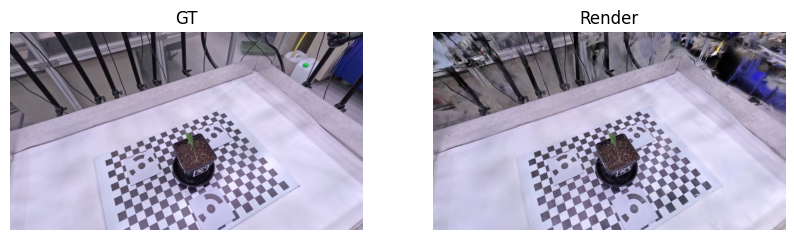

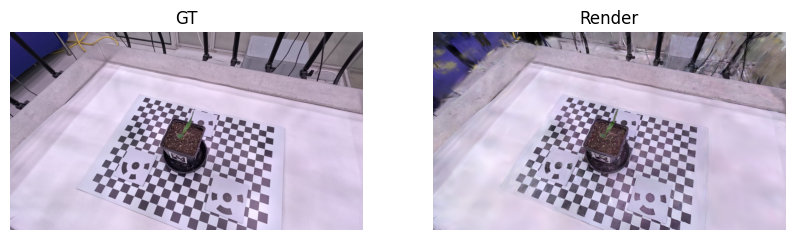

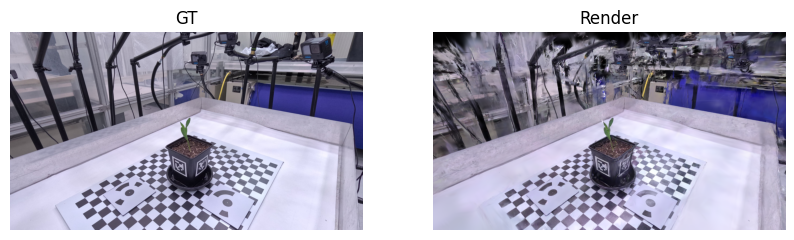

In [ ]:
import glob
from PIL import Image
from matplotlib import pyplot as plt

renders = sorted(glob.glob("/content/output/frame_0001_r4/**/ours_15000/**/renders/*.png", recursive=True))
gts     = sorted(glob.glob("/content/output/frame_0001_r4/**/ours_15000/**/gt/*.png", recursive=True))

print("renders:", len(renders), "gt:", len(gts))
for i in [0, 1, 2]:
    if i < len(renders) and i < len(gts):
        fig, ax = plt.subplots(1,2, figsize=(10,4))
        ax[0].imshow(Image.open(gts[i])); ax[0].set_title("GT"); ax[0].axis("off")
        ax[1].imshow(Image.open(renders[i])); ax[1].set_title("Render"); ax[1].axis("off")
        plt.show()

In [ ]:
!python -u metrics.py -m /content/output/frame_0001_r4


Scene: /content/output/frame_0001_r4
Method: ours_15000
Metric evaluation progress:   0% 0/10 [00:00<?, ?it/s]Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth

  0% 0.00/528M [00:00<?, ?B/s]
  2% 13.1M/528M [00:00<00:03, 138MB/s]
  6% 33.0M/528M [00:00<00:02, 179MB/s]
 10% 52.4M/528M [00:00<00:02, 190MB/s]
 14% 72.4M/528M [00:00<00:02, 197MB/s]
 17% 91.8M/528M [00:00<00:02, 199MB/s]
 21% 111M/528M [00:00<00:02, 188MB/s] 
 24% 129M/528M [00:00<00:02, 179MB/s]
 28% 148M/528M [00:00<00:02, 187MB/s]
 32% 170M/528M [00:00<00:01, 199MB/s]
 36% 191M/528M [00:01<00:01, 205MB/s]
 40% 211M/528M [00:01<00:01, 203MB/s]
 44% 230M/528M [00:01<00:01, 192MB/s]
 47% 249M/528M [00:01<00:01, 191MB/s]
 51% 267M/528M [00:01<00:01, 189MB/s]
 54% 286M/528M [00:01<00:01, 189MB/s]
 58% 304M/528M [00:01<00:01, 190MB/s]
 61% 322M/528M [00:01<00:01, 185MB/s]
 65% 343M/528M [00:01<00:00, 194MB/s]
 69% 364M/528M [00:01<00:00, 201MB/s]
 7

In [ ]:
!zip -r -q /content/frame_0001_r4_output.zip /content/output/frame_0001_r4
!ls -lh /content/frame_0001_r4_output.zip

-rw-r--r-- 1 root root 1.3G Mar  4 14:17 /content/frame_0001_r4_output.zip


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!cp /content/frame_0001_r4_output.zip "/content/drive/MyDrive/"
!ls -lh "/content/drive/MyDrive/frame_0001_r4_output.zip"

-rw------- 1 root root 1.3G Mar  4 14:28 /content/drive/MyDrive/frame_0001_r4_output.zip


In [ ]:
!unzip -o /content/frame_0001_yolosam.zip -d /content/data/frame_0001/frame_0001
# (adjust the destination to match your scene path)
!ls /content/data/frame_0001/frame_0001/yolosam/masks | wc -l

Archive:  /content/frame_0001_yolosam.zip
   creating: /content/data/frame_0001/frame_0001/initial_data_sample/maize_2/frame_0001/yolosam/
   creating: /content/data/frame_0001/frame_0001/initial_data_sample/maize_2/frame_0001/yolosam/bboxes/
  inflating: /content/data/frame_0001/frame_0001/initial_data_sample/maize_2/frame_0001/yolosam/bboxes/GX010051_20250818_183002_0001_3.pt  
  inflating: /content/data/frame_0001/frame_0001/initial_data_sample/maize_2/frame_0001/yolosam/bboxes/GX010009_20250818_183002_0001_0.pt  
  inflating: /content/data/frame_0001/frame_0001/initial_data_sample/maize_2/frame_0001/yolosam/bboxes/GX010208_20250818_183002_0001_18.pt  
  inflating: /content/data/frame_0001/frame_0001/initial_data_sample/maize_2/frame_0001/yolosam/bboxes/GX010081_20250818_183002_0001_10.pt  
  inflating: /content/data/frame_0001/frame_0001/initial_data_sample/maize_2/frame_0001/yolosam/bboxes/GX010141_20250818_183002_0001_15.pt  
  inflating: /content/data/frame_0001/frame_0001/initi

In [ ]:
!find /content/data -type d -name yolosam | head -n 20

/content/data/frame_0001/frame_0001/initial_data_sample/maize_2/frame_0001/yolosam


In [ ]:
!find /content/data -maxdepth 4 -type d -name images -print
!find /content/data -maxdepth 4 -type d -name sparse -print

/content/data/frame_0001/__MACOSX/frame_0001/images
/content/data/frame_0001/frame_0001/images
/content/data/frame_0001/__MACOSX/frame_0001/sparse
/content/data/frame_0001/frame_0001/sparse


In [ ]:
!SCENE="/content/data/frame_0001/frame_0001"; \
YOLO_SRC="/content/data/frame_0001/frame_0001/initial_data_sample/maize_2/frame_0001/yolosam"; \
mv "$YOLO_SRC" "$SCENE/yolosam"

In [ ]:
!ls /content/data/frame_0001/frame_0001/yolosam/masks | wc -l
!ls /content/data/frame_0001/frame_0001/yolosam/bboxes | wc -l

21
21


In [ ]:
!cd /content/data/frame_0001/frame_0001 && rm -f yolosam.zip && zip -r -q yolosam.zip yolosam
!ls -lh /content/data/frame_0001/frame_0001/yolosam.zip

-rw-r--r-- 1 root root 86K Mar  4 14:43 /content/data/frame_0001/frame_0001/yolosam.zip


In [ ]:
%%bash
set -euo pipefail

SCENE="/content/data/frame_0001/frame_0001"
BBOX_DIR="$SCENE/yolosam/bboxes"
MASK_DIR="$SCENE/yolosam/masks"

# bbox aliases: stem.pt -> stem.jpg.pt and stem.png.pt
for f in "$BBOX_DIR"/*.pt; do
  stem="$(basename "$f" .pt)"
  cp -n "$f" "$BBOX_DIR/${stem}.jpg.pt" || true
  cp -n "$f" "$BBOX_DIR/${stem}.png.pt" || true
done

# mask aliases: stem_000.png -> stem.jpg_000.png and stem.png_000.png
for m in "$MASK_DIR"/*_000.png; do
  base="$(basename "$m")"
  stem="${base%_000.png}"
  cp -n "$m" "$MASK_DIR/${stem}.jpg_000.png" || true
  cp -n "$m" "$MASK_DIR/${stem}.png_000.png" || true
done

echo "bbox files:" $(ls "$BBOX_DIR" | wc -l)
echo "mask files:" $(ls "$MASK_DIR" | wc -l)

bbox files: 63
mask files: 63


In [ ]:
!cp /content/Wheat-3DGS/run_3d_seg.py /content/Wheat-3DGS/run_3d_seg.py.bak

In [ ]:
!cp /content/Wheat-3DGS/run_3d_seg.py.bak /content/Wheat-3DGS/run_3d_seg.py

In [ ]:
!python -m py_compile /content/Wheat-3DGS/run_3d_seg.py && echo "compile OK"

compile OK


In [ ]:
from pathlib import Path
import re

p = Path("/content/Wheat-3DGS/run_3d_seg.py")
txt = p.read_text()

# Find the exact line and capture its indentation
m = re.search(r'^(?P<indent>[ \t]*)bboxes\s*=\s*torch\.load\(viewpoint_cam\.bbox_path\)\s*$', txt, flags=re.M)
if not m:
    raise RuntimeError("Could not find the bbox torch.load line to patch.")

indent = m.group("indent")

patch_lines = [
    "# --- PATCH: robust bbox_path resolution for plant single-instance setup ---",
    "bbox_path = viewpoint_cam.bbox_path",
    "if bbox_path is None:",
    "    # derive stem from image name / path",
    "    img_path = getattr(viewpoint_cam, 'image_path', None)",
    "    if img_path is None:",
    "        img_path = getattr(viewpoint_cam, 'image_name', None)",
    "    stem = None",
    "    if img_path is not None:",
    "        stem = Path(str(img_path)).name",
    "        for ext in ['.jpg', '.jpeg', '.png']:",
    "            if stem.endswith(ext):",
    "                stem = stem[:-len(ext)]",
    "    candidates = []",
    "    if stem is not None:",
    "        candidates += [",
    "            os.path.join(args.source_path, 'yolosam', 'bboxes', f'{stem}.pt'),",
    "            os.path.join(args.source_path, 'yolosam', 'bboxes', f'{stem}.jpg.pt'),",
    "            os.path.join(args.source_path, 'yolosam', 'bboxes', f'{stem}.png.pt'),",
    "        ]",
    "    for c in candidates:",
    "        if c and Path(c).exists():",
    "            bbox_path = c",
    "            break",
    "if bbox_path is None:",
    "    raise FileNotFoundError('Could not resolve bbox_path. Expected yolosam/bboxes/<stem>.pt')",
    "bboxes = torch.load(bbox_path)",
]

# Ensure required imports exist
if "from pathlib import Path" not in txt:
    txt = txt.replace("import os", "import os\nfrom pathlib import Path", 1) if "import os" in txt else "import os\nfrom pathlib import Path\n" + txt
if "import os" not in txt:
    txt = "import os\n" + txt

replacement = "\n".join(indent + line for line in patch_lines)

txt2 = re.sub(r'^[ \t]*bboxes\s*=\s*torch\.load\(viewpoint_cam\.bbox_path\)\s*$',
              replacement, txt, flags=re.M)

p.write_text(txt2)
print("Patched successfully.")

Patched successfully.


In [ ]:
!python -m py_compile /content/Wheat-3DGS/run_3d_seg.py && echo "compile OK"

compile OK


In [ ]:
from pathlib import Path
import re

p = Path("/content/Wheat-3DGS/run_3d_seg.py")
txt = p.read_text()

# Find the line and its indentation
m = re.search(r'^(?P<indent>[ \t]*)all_mask_paths\s*\+=\s*viewpoint_cam\.mask_paths\s*$', txt, flags=re.M)
if not m:
    raise RuntimeError("Could not find the all_mask_paths += viewpoint_cam.mask_paths line to patch.")
indent = m.group("indent")

patch_lines = [
    "# --- PATCH: robust mask_paths resolution for plant single-instance setup ---",
    "mask_paths = viewpoint_cam.mask_paths",
    "if mask_paths is None:",
    "    img_path = getattr(viewpoint_cam, 'image_path', None)",
    "    if img_path is None:",
    "        img_path = getattr(viewpoint_cam, 'image_name', None)",
    "    stem = None",
    "    if img_path is not None:",
    "        stem = Path(str(img_path)).name",
    "        for ext in ['.jpg', '.jpeg', '.png']:",
    "            if stem.endswith(ext):",
    "                stem = stem[:-len(ext)]",
    "    candidates = []",
    "    if stem is not None:",
    "        candidates += [",
    "            os.path.join(args.source_path, 'yolosam', 'masks', f'{stem}_000.png'),",
    "            os.path.join(args.source_path, 'yolosam', 'masks', f'{stem}.jpg_000.png'),",
    "            os.path.join(args.source_path, 'yolosam', 'masks', f'{stem}.png_000.png'),",
    "        ]",
    "    found = None",
    "    for c in candidates:",
    "        if c and Path(c).exists():",
    "            found = c",
    "            break",
    "    if found is None:",
    "        raise FileNotFoundError('Could not resolve mask path. Expected yolosam/masks/<stem>_000.png')",
    "    mask_paths = [found]  # single instance per image",
    "all_mask_paths += mask_paths",
]

replacement = "\n".join(indent + line for line in patch_lines)

txt2 = re.sub(r'^[ \t]*all_mask_paths\s*\+=\s*viewpoint_cam\.mask_paths\s*$',
              replacement, txt, flags=re.M)

# Ensure imports exist
if "from pathlib import Path" not in txt2:
    if "import os" in txt2:
        txt2 = txt2.replace("import os", "import os\nfrom pathlib import Path", 1)
    else:
        txt2 = "import os\nfrom pathlib import Path\n" + txt2

p.write_text(txt2)
print("Patched mask_paths successfully.")

Patched mask_paths successfully.


In [ ]:
!python -m py_compile /content/Wheat-3DGS/run_3d_seg.py && echo "compile OK"

compile OK


In [ ]:
from pathlib import Path
import re

p = Path("/content/Wheat-3DGS/run_3d_seg.py")
txt = p.read_text()

pattern = r'^(?P<indent>[ \t]*)bboxes\s*=\s*torch\.load\(viewpoint_cam\.bbox_path\)\s*/\s*viewpoint_cam\.resolution_scale\s*$'
m = re.search(pattern, txt, flags=re.M)
if not m:
    raise RuntimeError("Could not find the bbox load line inside find_match to patch.")

indent = m.group("indent")

patch_lines = [
    "# --- PATCH: robust bbox_path in find_match ---",
    "bbox_path = viewpoint_cam.bbox_path",
    "if bbox_path is None:",
    "    img_path = getattr(viewpoint_cam, 'image_path', None)",
    "    if img_path is None:",
    "        img_path = getattr(viewpoint_cam, 'image_name', None)",
    "    stem = None",
    "    if img_path is not None:",
    "        stem = Path(str(img_path)).name",
    "        for ext in ['.jpg', '.jpeg', '.png']:",
    "            if stem.endswith(ext):",
    "                stem = stem[:-len(ext)]",
    "    candidates = []",
    "    if stem is not None:",
    "        candidates += [",
    "            os.path.join(args.source_path, 'yolosam', 'bboxes', f'{stem}.pt'),",
    "            os.path.join(args.source_path, 'yolosam', 'bboxes', f'{stem}.jpg.pt'),",
    "            os.path.join(args.source_path, 'yolosam', 'bboxes', f'{stem}.png.pt'),",
    "        ]",
    "    for c in candidates:",
    "        if c and Path(c).exists():",
    "            bbox_path = c",
    "            break",
    "if bbox_path is None:",
    "    raise FileNotFoundError('Could not resolve bbox_path inside find_match')",
    "bboxes = torch.load(bbox_path) / viewpoint_cam.resolution_scale",
]

replacement = "\n".join(indent + line for line in patch_lines)

txt2 = re.sub(pattern, replacement, txt, flags=re.M)
# Ensure imports
if "from pathlib import Path" not in txt2:
    if "import os" in txt2:
        txt2 = txt2.replace("import os", "import os\nfrom pathlib import Path", 1)
    else:
        txt2 = "import os\nfrom pathlib import Path\n" + txt2

p.write_text(txt2)
print("Patched find_match bbox load.")

Patched find_match bbox load.


In [ ]:
!python -m py_compile /content/Wheat-3DGS/run_3d_seg.py && echo "compile OK"

compile OK


In [ ]:
from pathlib import Path
import re

p = Path("/content/Wheat-3DGS/run_3d_seg.py")
txt = p.read_text()

# We'll patch the assert line by inserting a guard right before it.
target = r'^(?P<indent>[ \t]*)assert p in viewpoint_cam\.mask_paths, f"\{p\} not found in current image\'s masks"\s*$'
m = re.search(target, txt, flags=re.M)
if not m:
    raise RuntimeError("Could not find the assert line in find_match to patch.")
indent = m.group("indent")

guard_lines = [
    "# --- PATCH: ensure mask_paths exists inside find_match ---",
    "if getattr(viewpoint_cam, 'mask_paths', None) is None:",
    "    img_path = getattr(viewpoint_cam, 'image_path', None)",
    "    if img_path is None:",
    "        img_path = getattr(viewpoint_cam, 'image_name', None)",
    "    stem = None",
    "    if img_path is not None:",
    "        stem = Path(str(img_path)).name",
    "        for ext in ['.jpg', '.jpeg', '.png']:",
    "            if stem.endswith(ext):",
    "                stem = stem[:-len(ext)]",
    "    candidates = []",
    "    if stem is not None:",
    "        candidates += [",
    "            os.path.join(args.source_path, 'yolosam', 'masks', f'{stem}_000.png'),",
    "            os.path.join(args.source_path, 'yolosam', 'masks', f'{stem}.jpg_000.png'),",
    "            os.path.join(args.source_path, 'yolosam', 'masks', f'{stem}.png_000.png'),",
    "        ]",
    "    found = None",
    "    for c in candidates:",
    "        if c and Path(c).exists():",
    "            found = c",
    "            break",
    "    if found is None:",
    "        raise FileNotFoundError('Could not resolve mask path inside find_match')",
    "    viewpoint_cam.mask_paths = [found]",
]

replacement = "\n".join(indent + line for line in guard_lines) + "\n" + (m.group(0))

txt2 = re.sub(target, replacement, txt, flags=re.M)

# ensure imports
if "from pathlib import Path" not in txt2:
    if "import os" in txt2:
        txt2 = txt2.replace("import os", "import os\nfrom pathlib import Path", 1)
    else:
        txt2 = "import os\nfrom pathlib import Path\n" + txt2

p.write_text(txt2)
print("Patched find_match mask_paths.")

Patched find_match mask_paths.


In [ ]:
!python -m py_compile /content/Wheat-3DGS/run_3d_seg.py && echo "compile OK"

compile OK


In [ ]:
!SCENE="/content/data/frame_0001/frame_0001"; \
python -u /content/Wheat-3DGS/run_3d_seg.py \
  -s "$SCENE" \
  -m /content/output/frame_0001_r4 \
  --resolution 4 \
  --iou_threshold 0.6 \
  --exp_name plant_run1

Optimizing /content/output/frame_0001_r4
Load iteration -1, Resolution 4
Loading trained model at iteration 15000
No directory of saved bounding boxes found!
No directory of saved segmentation masks found!
Reading camera 1/21/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))
Reading camera 21/21
Train Cam list with 11 cams: ['GX010009_20250818_183002_0001_0', 'GX010030_20250818_183002_0001_1', 'GX010046_20250818_183002_0001_2', 'GX010051_20250818_183002_0001_3', 'GX010059_20250818_183002_0001_4', 'GX010062_20250818_183002_0001_5', 'GX010067_20250818_183002_0001_6', 'GX010068_20250818_183002_0001_7', 'GX010070_20250818_183002_0001_8', 'GX010078_20250818_183002_0001_9', 'GX010081_20250818_183002_0001_10']
Test Cam list with 10 cams: ['GX010089_20250818_183002_0001_11', 'GX010102_20250818_183002_0001_12', 'GX010127_20250818_183002_0001_13', 'GX010134_20250818_183002_0001_

In [ ]:
!find /content/output/frame_0001_r4 -maxdepth 6 -type d | grep -i plant_run1 | head -n 80
!find /content/output/frame_0001_r4 -maxdepth 8 -type f | grep -E "png|mp4" | head -n 80

/content/output/frame_0001_r4/wheat-head/plant_run1
/content/output/frame_0001_r4/wheat-head/plant_run1/2DSeg
/content/output/frame_0001_r4/wheat-head/plant_run1/count
/content/output/frame_0001_r4/wheat-head/plant_run1/ply
/content/output/frame_0001_r4/wheat-head/plant_run1/img
/content/output/frame_0001_r4/wheat-head/plant_run1/img/0001
/content/output/frame_0001_r4/train/ours_15000/gt/00004.png
/content/output/frame_0001_r4/train/ours_15000/gt/00009.png
/content/output/frame_0001_r4/train/ours_15000/gt/00006.png
/content/output/frame_0001_r4/train/ours_15000/gt/00003.png
/content/output/frame_0001_r4/train/ours_15000/gt/00001.png
/content/output/frame_0001_r4/train/ours_15000/gt/00002.png
/content/output/frame_0001_r4/train/ours_15000/gt/00000.png
/content/output/frame_0001_r4/train/ours_15000/gt/00007.png
/content/output/frame_0001_r4/train/ours_15000/gt/00005.png
/content/output/frame_0001_r4/train/ours_15000/gt/00010.png
/content/output/frame_0001_r4/train/ours_15000/gt/00008.png

In [ ]:
!python -u eval_wheatgs.py \
  -s /content/data/frame_0001/frame_0001 \
  -m /content/output/frame_0001_r4 \
  --exp_name plant_run1 \
  --skip_train

Looking for config file in /content/output/frame_0001_r4/cfg_args
Config file found: /content/output/frame_0001_r4/cfg_args
Rendering /content/output/frame_0001_r4/plant_run1
Loading trained model at iteration 15000
No directory of saved bounding boxes found!
No directory of saved segmentation masks found!
Reading camera 1/21/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))
Reading camera 21/21
Train Cam list with 11 cams: ['GX010009_20250818_183002_0001_0', 'GX010030_20250818_183002_0001_1', 'GX010046_20250818_183002_0001_2', 'GX010051_20250818_183002_0001_3', 'GX010059_20250818_183002_0001_4', 'GX010062_20250818_183002_0001_5', 'GX010067_20250818_183002_0001_6', 'GX010068_20250818_183002_0001_7', 'GX010070_20250818_183002_0001_8', 'GX010078_20250818_183002_0001_9', 'GX010081_20250818_183002_0001_10']
Test Cam list with 10 cams: ['GX010089_20250818_183002_0001_11', '

In [ ]:
# saving stuff

In [ ]:
# 1) Output (model + segmentation)
!zip -r -q /content/frame_0001_r4_output.zip /content/output/frame_0001_r4
!cp /content/frame_0001_r4_output.zip /content/drive/MyDrive/

# 2) yolosam only (small)
!zip -r -q /content/frame_0001_yolosam_colab.zip /content/data/frame_0001/frame_0001/yolosam
!cp /content/frame_0001_yolosam_colab.zip /content/drive/MyDrive/

# 3) patched script
!cp /content/Wheat-3DGS/run_3d_seg.py /content/drive/MyDrive/run_3d_seg_patched.py

In [ ]:
!ls -lh /content/drive/MyDrive/ | grep -E "frame_0001_r4_output|frame_0001_yolosam_colab|run_3d_seg_patched"

ls: '/content/drive/MyDrive/Présentation cursus 2ème année - 11 mai 2023': No such file or directory
-rw------- 1 root root 1.5G Mar  4 15:02 frame_0001_r4_output.zip
-rw------- 1 root root 265K Mar  4 15:02 frame_0001_yolosam_colab.zip
-rw------- 1 root root  26K Mar  4 15:02 run_3d_seg_patched.py


In [ ]:
!mkdir -p /content/restored

In [ ]:
!unzip -q -o /content/output.zip -d /content/restored

In [ ]:
!unzip -q -o /content/data.zip -d /content/data

In [ ]:
!ls -lah /content/restored | head -n 50
!find /content/restored -maxdepth 3 -type d -name output -print

total 16K
drwxr-xr-x 4 root root 4.0K Mar  4 22:30 .
drwxr-xr-x 1 root root 4.0K Mar  4 22:29 ..
drwxr-xr-x 3 root root 4.0K Mar  4 22:30 __MACOSX
drwxr-xr-x 3 root root 4.0K Mar  4 14:36 output
/content/restored/__MACOSX/output
/content/restored/output


In [ ]:
!find /content/restored -maxdepth 6 -type d -name "frame_0001_r4" -print

/content/restored/__MACOSX/output/frame_0001_r4
/content/restored/output/frame_0001_r4


In [ ]:
!find /content/restored -type f -name "*.ply" | head -n 50

/content/restored/__MACOSX/output/frame_0001_r4/point_cloud/iteration_15000/._point_cloud.ply
/content/restored/__MACOSX/output/frame_0001_r4/point_cloud/iteration_7000/._point_cloud.ply
/content/restored/__MACOSX/output/frame_0001_r4/._input.ply
/content/restored/output/frame_0001_r4/point_cloud/iteration_15000/point_cloud.ply
/content/restored/output/frame_0001_r4/point_cloud/iteration_7000/point_cloud.ply
/content/restored/output/frame_0001_r4/input.ply


In [ ]:
!find /content/restored -type d | grep -i plant_run1 | head -n 50

In [ ]:
!rm -rf /content/output/frame_0001_r4
!mkdir -p /content/output
!cp -r /content/restored/output/frame_0001_r4 /content/output/
!ls -lah /content/output/frame_0001_r4 | head -n 40

total 1.1G
drwxr-xr-x 5 root root 4.0K Mar  4 22:32 .
drwxr-xr-x 3 root root 4.0K Mar  4 22:32 ..
-rw-r--r-- 1 root root 8.8K Mar  4 22:32 cameras.json
-rw-r--r-- 1 root root  203 Mar  4 22:32 cfg_args
-rw-r--r-- 1 root root 574M Mar  4 22:32 chkpnt15000.pth
-rw-r--r-- 1 root root 522M Mar  4 22:32 chkpnt7000.pth
-rw-r--r-- 1 root root  24M Mar  4 22:32 events.out.tfevents.1772631979.045862ad87f5.10572.0
-rw-r--r-- 1 root root 425K Mar  4 22:32 input.ply
-rw-r--r-- 1 root root 1.2K Mar  4 22:32 per_view.json
drwxr-xr-x 4 root root 4.0K Mar  4 22:32 point_cloud
-rw-r--r-- 1 root root  112 Mar  4 22:32 results.json
drwxr-xr-x 3 root root 4.0K Mar  4 22:32 test
drwxr-xr-x 3 root root 4.0K Mar  4 22:32 train


In [ ]:
!find /content/output/frame_0001_r4 -maxdepth 6 -type d | grep -i plant_run1 | head -n 50
!find /content/output/frame_0001_r4 -maxdepth 4 -type d | grep -i wheat | head -n 50

In [ ]:
!find /content/output/frame_0001_r4 -type f -name "gaussians.ply" -print

In [ ]:
!ls /content/data/data/frame_0001/frame_0001/yolosam/masks | wc -l
!ls /content/data/data/frame_0001/frame_0001/yolosam/bboxes | wc -l

63
63


In [ ]:
SCENE="/content/data/data/frame_0001/frame_0001"

In [ ]:
MODEL="/content/output/frame_0001_r4"

In [ ]:
!SCENE="/content/data/data/frame_0001/frame_0001"; \
ls "$SCENE" && ls "$SCENE/yolosam/masks" | wc -l && ls "$SCENE/yolosam/bboxes" | wc -l

yolosam
63
63


In [ ]:
!SCENE="/content/data/data/frame_0001/frame_0001"; \
python -u /content/Wheat-3DGS/run_3d_seg.py \
  -s "$SCENE" \
  -m /content/output/frame_0001_r4 \
  --resolution 4 \
  --iou_threshold 0.6 \
  --exp_name plant_run1

python3: can't open file '/content/Wheat-3DGS/run_3d_seg.py': [Errno 2] No such file or directory


In [ ]:
%cd /content
!rm -rf Wheat-3DGS
!git clone --recursive https://github.com/zdwww/Wheat-3DGS.git
%cd /content/Wheat-3DGS
!ls

/content
Cloning into 'Wheat-3DGS'...
remote: Enumerating objects: 321, done.
remote: Counting objects: 100% (321/321), done.
remote: Compressing objects: 100% (225/225), done.
remote: Total 321 (delta 151), reused 252 (delta 85), pack-reused 0 (from 0)
Receiving objects: 100% (321/321), 16.38 MiB | 17.41 MiB/s, done.
Resolving deltas: 100% (151/151), done.
Submodule 'submodules/diff-gaussian-rasterization' (https://github.com/ashawkey/diff-gaussian-rasterization.git) registered for path 'submodules/diff-gaussian-rasterization'
Submodule 'submodules/flashsplat-rasterization' (https://github.com/florinshen/flashsplat-rasterization.git) registered for path 'submodules/flashsplat-rasterization'
Submodule 'submodules/simple-knn' (https://gitlab.inria.fr/bkerbl/simple-knn.git) registered for path 'submodules/simple-knn'
Cloning into '/content/Wheat-3DGS/submodules/diff-gaussian-rasterization'...
remote: Enumerating objects: 248, done.        
remote: Counting objects: 100% (90/90), done.   

In [ ]:
!pip -q install --upgrade pip setuptools wheel
!apt-get update -qq
!apt-get install -y -qq build-essential cmake ninja-build ffmpeg
!pip -q install numpy scipy pillow tqdm pyyaml opencv-python matplotlib plyfile rich wandb ffmpeg-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 54.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 60.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package ninja-build.
(Reading database ... 121852 files and directories currently installed.)
Preparing to unpack .../ninja-build_1.10.1-1_amd64.deb ...
Unpacking ninja-build (1.10.1-1) ...
Setting up ninja-build (1.10.1-1) ...
Processing triggers for man-db (2.10.2-1) ...


In [ ]:
!pip install -q --no-build-isolation ./submodules/diff-gaussian-rasterization
!pip install -q --no-build-isolation ./submodules/simple-knn

  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
%%bash
set -e

TORCH_LIB=$(python - <<'PY'
import torch, os
print(os.path.join(os.path.dirname(torch.__file__), "lib"))
PY
)

echo "Torch lib dir: $TORCH_LIB"
export LD_LIBRARY_PATH="$TORCH_LIB:$LD_LIBRARY_PATH"
echo "LD_LIBRARY_PATH now starts with: $(echo $LD_LIBRARY_PATH | cut -d: -f1)"

python -c "from simple_knn._C import distCUDA2; print('simple_knn OK')"

Torch lib dir: /usr/local/lib/python3.12/dist-packages/torch/lib
LD_LIBRARY_PATH now starts with: /usr/local/lib/python3.12/dist-packages/torch/lib
simple_knn OK


In [ ]:
!ls /content/data/data/frame_0001/frame_0001 | head
!ls /content/output/frame_0001_r4 | head

yolosam
cameras.json
cfg_args
chkpnt15000.pth
chkpnt7000.pth
events.out.tfevents.1772631979.045862ad87f5.10572.0
input.ply
per_view.json
point_cloud
results.json
test


In [ ]:
!cp /content/run_3d_seg_patched.py /content/Wheat-3DGS/run_3d_seg.py
!python -m py_compile /content/Wheat-3DGS/run_3d_seg.py && echo "patched run_3d_seg OK"

patched run_3d_seg OK


In [ ]:
%cd /content/Wheat-3DGS
!pip install -q --no-build-isolation ./submodules/flashsplat-rasterization

/content/Wheat-3DGS
  Preparing metadata (pyproject.toml) ... done


In [ ]:
!python -c "import flashsplat_rasterization; print('flashsplat OK')"

flashsplat OK


In [ ]:
!echo "IMAGES dirs:"; find /content -maxdepth 6 -type d -name images -print
!echo "SPARSE/0 dirs:"; find /content -maxdepth 8 -type d -path "*/sparse/0" -print
!echo "YOLOSAM dirs:"; find /content -maxdepth 8 -type d -name yolosam -print

IMAGES dirs:
SPARSE/0 dirs:
YOLOSAM dirs:
/content/data/__MACOSX/data/frame_0001/frame_0001/yolosam
/content/data/data/frame_0001/frame_0001/yolosam


In [ ]:
!unzip -q -o /content/frame_0001.zip -d /content/data

In [ ]:
!SCENE1="/content/data/frame_0001"; \
echo "SCENE=$SCENE1"; \
ls "$SCENE1"; \
ls "$SCENE1/images" | head; \
ls "$SCENE1/sparse/0" | head

SCENE=/content/data/frame_0001
colmap.txt  images  sparse
GX010009_20250818_183002_0001_0.jpg
GX010030_20250818_183002_0001_1.jpg
GX010046_20250818_183002_0001_2.jpg
GX010051_20250818_183002_0001_3.jpg
GX010059_20250818_183002_0001_4.jpg
GX010062_20250818_183002_0001_5.jpg
GX010067_20250818_183002_0001_6.jpg
GX010068_20250818_183002_0001_7.jpg
GX010070_20250818_183002_0001_8.jpg
GX010078_20250818_183002_0001_9.jpg
cameras.bin
cameras.txt
images.bin
images.txt
points3D.bin
points3D.txt


In [ ]:
!SCENE1="/content/data/frame_0001"; \
YOLO_SRC="/content/data/data/frame_0001/frame_0001/yolosam"; \
rm -rf "$SCENE1/yolosam"; \
cp -R "$YOLO_SRC" "$SCENE1/yolosam"; \
echo "masks:"; ls "$SCENE1/yolosam/masks" | wc -l; \
echo "bboxes:"; ls "$SCENE1/yolosam/bboxes" | wc -l

masks:
63
bboxes:
63


In [ ]:
!SCENE2="/content/data/frame_0001"; \
test -d "$SCENE2/images" && echo "✅ images"; \
test -d "$SCENE2/sparse/0" && echo "✅ sparse/0"; \
test -d "$SCENE2/yolosam/masks" && echo "✅ masks"; \
test -d "$SCENE2/yolosam/bboxes" && echo "✅ bboxes"

✅ images
✅ sparse/0
✅ masks
✅ bboxes


In [ ]:
!cp /content/run_3d_seg_patched.py /content/Wheat-3DGS/run_3d_seg.py
!python -m py_compile /content/Wheat-3DGS/run_3d_seg.py && echo "patched OK"

patched OK


In [ ]:
!SCENE3="/content/data/frame_0001"; \
python -u /content/Wheat-3DGS/run_3d_seg.py \
  -s "$SCENE3" \
  -m /content/output/frame_0001_r4 \
  --resolution 4 \
  --iou_threshold 0.6 \
  --exp_name plant_run1

Optimizing /content/output/frame_0001_r4
Load iteration -1, Resolution 4
Loading trained model at iteration 15000
No directory of saved bounding boxes found!
No directory of saved segmentation masks found!
Reading camera 1/21/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))
Reading camera 21/21
Train Cam list with 11 cams: ['GX010009_20250818_183002_0001_0', 'GX010030_20250818_183002_0001_1', 'GX010046_20250818_183002_0001_2', 'GX010051_20250818_183002_0001_3', 'GX010059_20250818_183002_0001_4', 'GX010062_20250818_183002_0001_5', 'GX010067_20250818_183002_0001_6', 'GX010068_20250818_183002_0001_7', 'GX010070_20250818_183002_0001_8', 'GX010078_20250818_183002_0001_9', 'GX010081_20250818_183002_0001_10']
Test Cam list with 10 cams: ['GX010089_20250818_183002_0001_11', 'GX010102_20250818_183002_0001_12', 'GX010127_20250818_183002_0001_13', 'GX010134_20250818_183002_0001_

In [ ]:
!EXP="/content/output/frame_0001_r4/wheat-head/plant_run1"; \
echo "Listing EXP:"; ls -lah "$EXP" || true; \
echo "Find gaussians/counts:"; \
find /content/output/frame_0001_r4 -type f \( -name "gaussians.ply" -o -name "*.pt" -o -name "*count*" -o -name "*mask*" \) | grep -i plant_run1 | head -n 80

Listing EXP:
total 200M
drwxr-xr-x 6 root root 4.0K Mar  4 23:19 .
drwxr-xr-x 3 root root 4.0K Mar  4 23:00 ..
drwxr-xr-x 2 root root 4.0K Mar  4 23:18 2DSeg
drwxr-xr-x 2 root root 4.0K Mar  4 23:19 count
-rw-r--r-- 1 root root   38 Mar  4 23:18 experiment.txt
-rw-r--r-- 1 root root 200M Mar  4 23:19 gaussians.ply
drwxr-xr-x 3 root root 4.0K Mar  4 23:19 img
drwxr-xr-x 2 root root 4.0K Mar  4 23:19 ply
-rw-r--r-- 1 root root   83 Mar  4 23:19 results.csv
Find gaussians/counts:
/content/output/frame_0001_r4/wheat-head/plant_run1/2DSeg/GX010078_20250818_183002_0001_9.pt
/content/output/frame_0001_r4/wheat-head/plant_run1/2DSeg/GX010059_20250818_183002_0001_4.pt
/content/output/frame_0001_r4/wheat-head/plant_run1/2DSeg/GX010070_20250818_183002_0001_8.pt
/content/output/frame_0001_r4/wheat-head/plant_run1/2DSeg/GX010148_20250818_183003_0001_16.pt
/content/output/frame_0001_r4/wheat-head/plant_run1/2DSeg/GX010046_20250818_183002_0001_2.pt
/content/output/frame_0001_r4/wheat-head/plant_run1/

In [ ]:
!ls /content/Wheat-3DGS | egrep "render|eval|viewer|video|vis|wheat" || true

eval.sh
eval_wheatgs.py
gaussian_renderer
render_360.py
render.py
run_wheat_3dgs.sh
vis_cam.py
wheat3dgsviewer
wheatheadsmorphology


In [ ]:
!cd /content && \
zip -r frame_0001_r4_outputs_and_seg.zip \
  output/frame_0001_r4 \
  data/frame_0001/yolosam \
  -x "*/__MACOSX/*"
!ls -lh /content/frame_0001_r4_outputs_and_seg.zip

  adding: output/frame_0001_r4/ (stored 0%)
  adding: output/frame_0001_r4/cameras.json (deflated 66%)
  adding: output/frame_0001_r4/train/ (stored 0%)
  adding: output/frame_0001_r4/train/ours_15000/ (stored 0%)
  adding: output/frame_0001_r4/train/ours_15000/renders/ (stored 0%)
  adding: output/frame_0001_r4/train/ours_15000/renders/00002.png (deflated 0%)
  adding: output/frame_0001_r4/train/ours_15000/renders/00009.png (deflated 0%)
  adding: output/frame_0001_r4/train/ours_15000/renders/00001.png (deflated 0%)
  adding: output/frame_0001_r4/train/ours_15000/renders/00007.png (deflated 0%)
  adding: output/frame_0001_r4/train/ours_15000/renders/00005.png (deflated 0%)
  adding: output/frame_0001_r4/train/ours_15000/renders/00000.png (deflated 0%)
  adding: output/frame_0001_r4/train/ours_15000/renders/00006.png (deflated 0%)
  adding: output/frame_0001_r4/train/ours_15000/renders/00008.png (deflated 0%)
  adding: output/frame_0001_r4/train/ours_15000/renders/00010.png (deflated 0

In [ ]:
!cd /content && zip -r plant_run1_outputs.zip \
  output/frame_0001_r4/wheat-head/plant_run1 \
  output/frame_0001_r4/cfg_args \
  output/frame_0001_r4/point_cloud/iteration_15000/point_cloud.ply \
  data/frame_0001/yolosam \
  -x "*/__MACOSX/*"
!ls -lh /content/plant_run1_outputs.zip

  adding: output/frame_0001_r4/wheat-head/plant_run1/ (stored 0%)
  adding: output/frame_0001_r4/wheat-head/plant_run1/results.csv (deflated 8%)
  adding: output/frame_0001_r4/wheat-head/plant_run1/2DSeg/ (stored 0%)
  adding: output/frame_0001_r4/wheat-head/plant_run1/2DSeg/GX010078_20250818_183002_0001_9.pt (deflated 100%)
  adding: output/frame_0001_r4/wheat-head/plant_run1/2DSeg/GX010059_20250818_183002_0001_4.pt (deflated 100%)
  adding: output/frame_0001_r4/wheat-head/plant_run1/2DSeg/GX010070_20250818_183002_0001_8.pt (deflated 100%)
  adding: output/frame_0001_r4/wheat-head/plant_run1/2DSeg/GX010148_20250818_183003_0001_16.pt (deflated 100%)
  adding: output/frame_0001_r4/wheat-head/plant_run1/2DSeg/GX010046_20250818_183002_0001_2.pt (deflated 100%)
  adding: output/frame_0001_r4/wheat-head/plant_run1/2DSeg/GX010156_20250818_183003_0001_17.pt (deflated 100%)
  adding: output/frame_0001_r4/wheat-head/plant_run1/2DSeg/GX010009_20250818_183002_0001_0.pt (deflated 100%)
  adding: o

In [ ]:
!unzip -q -o /content/frame_0001.zip -d /content/data

In [ ]:
!unzip -q -o /content/data.zip -d /content/data

In [ ]:
!unzip -q -o /content/output.zip -d /content/data

[/content/output.zip]
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of /content/output.zip or
        /content/output.zip.zip, and cannot find /content/output.zip.ZIP, period.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!ls -lh /content/drive/MyDrive | head
!find /content/drive/MyDrive -maxdepth 4 -type f \( -name "*frame_0001*.zip" -o -name "*output*.zip" \) -print

ls: '/content/drive/MyDrive/Présentation cursus 2ème année - 11 mai 2023': No such file or directory
total 1.5G
-rw------- 1 root root 400K Dec 19 21:41 26Subject AnticorruptionS. Mercoli.docx
-rw------- 1 root root  175 Mar  5 12:41 A2 - Español.gdoc
-rw------- 1 root root  175 Feb 24  2025 A3_cell_distance_log.gsheet
-rw------- 1 root root  175 Feb 24  2025 A3_cell_intensity_log.gsheet
-rw------- 1 root root  175 Jan 27  2023 Aa.gdoc
drwx------ 2 root root 4.0K Sep 20  2022 AICC
drwx------ 2 root root 4.0K Sep 20  2022 Algebre Linéaire 
-rw------- 1 root root  175 Nov  9 14:08 AML-P1-description.gdoc
-rw------- 1 root root  175 Dec 11 12:12 AML_RL_Tuto1.gslides
/content/drive/MyDrive/frame_0001_r4_output.zip
/content/drive/MyDrive/frame_0001_yolosam_colab.zip


In [ ]:
!cp "/content/drive/MyDrive/frame_0001_r4_output.zip" /content/  # if you have it
!ls -lh /content/*.zip

cp: cannot stat '/content/drive/MyDrive/frame_0001.zip': No such file or directory
-rw-r--r-- 1 root root 329K Mar  5 12:56 /content/data.zip
-rw------- 1 root root 1.3G Mar  5 13:36 /content/frame_0001_r4_output.zip
-rw-r--r-- 1 root root  85M Mar  5 12:58 /content/frame_0001.zip
-rw-r--r-- 1 root root 180M Mar  5 13:36 /content/output1.zip
-rw-r--r-- 1 root root  60M Mar  5 13:35 /content/output.zip


In [ ]:
!unzip -q -o /content/frame_0001_r4_output.zip -d /content/data/output

In [ ]:
SCENE="/content/data/frame_0001"
YOLO_SRC="/content/data/data/frame_0001/frame_0001/yolosam"

# sanity
!ls -d "$SCENE/images" "$SCENE/sparse/0" || true
!ls -d "$YOLO_SRC/masks" "$YOLO_SRC/bboxes" || true

# copy yolosam into the real SCENE folder
!rm -rf "$SCENE/yolosam"
!cp -r "$YOLO_SRC" "$SCENE/yolosam"

!echo "After copy:"
!ls -d "$SCENE/yolosam/masks" "$SCENE/yolosam/bboxes"
!echo "counts:"
!ls "$SCENE/yolosam/masks" | wc -l
!ls "$SCENE/yolosam/bboxes" | wc -l

/content/data/frame_0001/images  /content/data/frame_0001/sparse/0
/content/data/data/frame_0001/frame_0001/yolosam/bboxes
/content/data/data/frame_0001/frame_0001/yolosam/masks
After copy:
/content/data/frame_0001/yolosam/bboxes  /content/data/frame_0001/yolosam/masks
counts:
63
63


In [ ]:
%%bash
MODEL="/content/data/output/content/output/frame_0001_r4"

echo "MODEL = $MODEL"
ls -lah "$MODEL" | head -n 30
ls -lah "$MODEL/point_cloud" | head -n 30
ls -lah "$MODEL/point_cloud/iteration_15000" | head -n 20

MODEL = /content/data/output/content/output/frame_0001_r4
total 1.1G
drwxr-xr-x 5 root root 4.0K Mar  4 14:12 .
drwxr-xr-x 3 root root 4.0K Mar  5 13:36 ..
-rw-r--r-- 1 root root 8.8K Mar  4 13:46 cameras.json
-rw-r--r-- 1 root root  203 Mar  4 13:46 cfg_args
-rw-r--r-- 1 root root 574M Mar  4 14:10 chkpnt15000.pth
-rw-r--r-- 1 root root 522M Mar  4 13:56 chkpnt7000.pth
-rw-r--r-- 1 root root  24M Mar  4 14:10 events.out.tfevents.1772631979.045862ad87f5.10572.0
-rw-r--r-- 1 root root 425K Mar  4 13:46 input.ply
-rw-r--r-- 1 root root 1.2K Mar  4 14:12 per_view.json
drwxr-xr-x 4 root root 4.0K Mar  4 14:10 point_cloud
-rw-r--r-- 1 root root  112 Mar  4 14:12 results.json
drwxr-xr-x 3 root root 4.0K Mar  4 14:11 test
drwxr-xr-x 3 root root 4.0K Mar  4 14:11 train
total 16K
drwxr-xr-x 4 root root 4.0K Mar  4 14:10 .
drwxr-xr-x 5 root root 4.0K Mar  4 14:12 ..
drwxr-xr-x 2 root root 4.0K Mar  4 14:10 iteration_15000
drwxr-xr-x 2 root root 4.0K Mar  4 13:56 iteration_7000
total 200M
drwxr-x

In [ ]:
%%bash
SRC="/content/data/output/content/output/frame_0001_r4"
DEST="/content/output/frame_0001_r4"

mkdir -p /content/output
rm -rf "$DEST"

# Option A (fast): symlink
ln -s "$SRC" "$DEST"

echo "✅ Linked $DEST -> $SRC"
ls -lah /content/output | head -n 20

✅ Linked /content/output/frame_0001_r4 -> /content/data/output/content/output/frame_0001_r4
total 8.0K
drwxr-xr-x 2 root root 4.0K Mar  5 13:44 .
drwxr-xr-x 1 root root 4.0K Mar  5 13:44 ..
lrwxrwxrwx 1 root root   49 Mar  5 13:44 frame_0001_r4 -> /content/data/output/content/output/frame_0001_r4


In [ ]:
%%bash
cd /content/Wheat-3DGS

pip -q install -e submodules/diff-gaussian-rasterization
pip -q install -e submodules/simple-knn

# flashsplat folder name can vary; find it:
ls submodules | sed -n '1,200p'

diff-gaussian-rasterization
flashsplat-rasterization
simple-knn


In [ ]:
%%bash
cd /content/Wheat-3DGS
pip -q install -e submodules/flashsplat-rasterization

In [ ]:
%%bash
python - <<'PY'
import torch
print("torch:", torch.__version__, "cuda:", torch.version.cuda)
import diff_gaussian_rasterization, simple_knn
import flashsplat_rasterization
print("✅ imports ok")
PY

torch: 2.10.0+cu128 cuda: 12.8
✅ imports ok


In [ ]:
%%bash
SCENE="/content/data/frame_0001"
MODEL="/content/output/frame_0001_r4"

echo "SCENE checks:"
test -d "$SCENE/images" && echo "✅ images" || echo "❌ images missing"
test -d "$SCENE/sparse/0" && echo "✅ sparse/0" || echo "❌ sparse/0 missing"
test -d "$SCENE/yolosam/masks" && echo "✅ yolosam masks" || echo "❌ yolosam masks missing"
test -d "$SCENE/yolosam/bboxes" && echo "✅ yolosam bboxes" || echo "❌ yolosam bboxes missing"

echo
echo "MODEL checks:"
test -f "$MODEL/point_cloud/iteration_15000/point_cloud.ply" && echo "✅ point_cloud.ply" || echo "❌ point_cloud.ply missing"

SCENE checks:
✅ images
✅ sparse/0
✅ yolosam masks
✅ yolosam bboxes

MODEL checks:
✅ point_cloud.ply


In [ ]:
%%bash
pip -q install plyfile

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 kB 4.1 MB/s eta 0:00:00


In [ ]:
%%bash
SCENE="/content/data/frame_0001"
ALT="/content/data/data/frame_0001/frame_0001/yolosam"

echo "SCENE yolosam: $SCENE/yolosam"
echo "ALT  yolosam: $ALT"

if [ ! -d "$ALT/bboxes" ]; then
  echo "❌ ALT path not found: $ALT/bboxes"
  exit 1
fi

mkdir -p "$SCENE/yolosam/bboxes" "$SCENE/yolosam/masks"

# Copy anything missing
cp -n "$ALT/bboxes/"*.pt "$SCENE/yolosam/bboxes/" 2>/dev/null || true
cp -n "$ALT/masks/"*.png "$SCENE/yolosam/masks/" 2>/dev/null || true

echo "After copy:"
echo -n "bboxes: "; ls -1 "$SCENE/yolosam/bboxes" | wc -l
echo -n "masks: "; ls -1 "$SCENE/yolosam/masks" | wc -l

SCENE yolosam: /content/data/frame_0001/yolosam
ALT  yolosam: /content/data/data/frame_0001/frame_0001/yolosam
After copy:
bboxes: 63
masks: 63


In [ ]:
%%bash
SCENE="/content/data/frame_0001"
cd "$SCENE/yolosam/bboxes"

for pt in *.pt; do
  base="${pt%.pt}"
  # create alias like <base>.jpg.pt if it doesn't exist
  if [ ! -f "${base}.jpg.pt" ]; then
    ln -s "$pt" "${base}.jpg.pt" 2>/dev/null || cp -n "$pt" "${base}.jpg.pt"
  fi
done

echo "Done. Example:"
ls -1 | head -n 20

Done. Example:
GX010009_20250818_183002_0001_0.jpg.jpg.pt
GX010009_20250818_183002_0001_0.jpg.pt
GX010009_20250818_183002_0001_0.png.jpg.pt
GX010009_20250818_183002_0001_0.png.pt
GX010009_20250818_183002_0001_0.pt
GX010030_20250818_183002_0001_1.jpg.jpg.pt
GX010030_20250818_183002_0001_1.jpg.pt
GX010030_20250818_183002_0001_1.png.jpg.pt
GX010030_20250818_183002_0001_1.png.pt
GX010030_20250818_183002_0001_1.pt
GX010046_20250818_183002_0001_2.jpg.jpg.pt
GX010046_20250818_183002_0001_2.jpg.pt
GX010046_20250818_183002_0001_2.png.jpg.pt
GX010046_20250818_183002_0001_2.png.pt
GX010046_20250818_183002_0001_2.pt
GX010051_20250818_183002_0001_3.jpg.jpg.pt
GX010051_20250818_183002_0001_3.jpg.pt
GX010051_20250818_183002_0001_3.png.jpg.pt
GX010051_20250818_183002_0001_3.png.pt
GX010051_20250818_183002_0001_3.pt


In [ ]:
%%bash
SCENE="/content/data/frame_0001"

# sanity check
ls -d "$SCENE/yolosam/bboxes" "$SCENE/yolosam/masks"

# remove any old wrong folders
rm -rf "$SCENE/bboxes" "$SCENE/masks"

# create symlinks in the location the code expects
ln -s "$SCENE/yolosam/bboxes" "$SCENE/bboxes"
ln -s "$SCENE/yolosam/masks"  "$SCENE/masks"

echo "✅ now scene root has:"
ls -lah "$SCENE" | head -n 50
echo
echo "✅ counts:"
ls -1 "$SCENE/bboxes" | wc -l
ls -1 "$SCENE/masks" | wc -l

/content/data/frame_0001/yolosam/bboxes
/content/data/frame_0001/yolosam/masks
✅ now scene root has:
total 24K
drwxr-xr-x 5 root root 4.0K Mar  5 14:31 .
drwxr-xr-x 6 root root 4.0K Mar  5 13:36 ..
lrwxrwxrwx 1 root root   39 Mar  5 14:31 bboxes -> /content/data/frame_0001/yolosam/bboxes
-rw-r--r-- 1 root root  183 Feb 26 16:35 colmap.txt
drwxr-xr-x 2 root root 4.0K Feb 26 16:38 images
lrwxrwxrwx 1 root root   38 Mar  5 14:31 masks -> /content/data/frame_0001/yolosam/masks
drwxr-xr-x 3 root root 4.0K Feb 26 16:38 sparse
drwxr-xr-x 4 root root 4.0K Mar  5 13:41 yolosam

✅ counts:
105
63


In [ ]:
%%bash
cd /content/Wheat-3DGS
SCENE="/content/data/frame_0001"
MODEL="/content/output/frame_0001_r4"

python -u run_3d_seg.py \
  -s "$SCENE" \
  -m "$MODEL" \
  --resolution 4 \
  --iou_threshold 0.6 \
  --exp_name plant_run1

Optimizing /content/output/frame_0001_r4
Load iteration -1, Resolution 4
Loading trained model at iteration 15000
Reading camera 21/21
Train Cam list with 11 cams: ['GX010009_20250818_183002_0001_0', 'GX010030_20250818_183002_0001_1', 'GX010046_20250818_183002_0001_2', 'GX010051_20250818_183002_0001_3', 'GX010059_20250818_183002_0001_4', 'GX010062_20250818_183002_0001_5', 'GX010067_20250818_183002_0001_6', 'GX010068_20250818_183002_0001_7', 'GX010070_20250818_183002_0001_8', 'GX010078_20250818_183002_0001_9', 'GX010081_20250818_183002_0001_10']
Test Cam list with 10 cams: ['GX010089_20250818_183002_0001_11', 'GX010102_20250818_183002_0001_12', 'GX010127_20250818_183002_0001_13', 'GX010134_20250818_183002_0001_14', 'GX010141_20250818_183002_0001_15', 'GX010148_20250818_183003_0001_16', 'GX010156_20250818_183003_0001_17', 'GX010208_20250818_183002_0001_18', 'GX010279_20250818_183002_0001_19', 'GX010319_20250818_183002_0001_20']
Cameras extent: 0.504995803222354
Loading Training Cameras
L

/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))
Processing Masks:   0%|          | 0/11 [00:00<?, ?it/s]
multi-view optimize: 2it [00:00, 81.33it/s]

multi-view optimize: 2it [00:00, 3571.14it/s]
/content/Wheat-3DGS/run_3d_seg.py:366: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  mask = Image.fromarray(np.where(pred_seg, 255, 0).astype(np.uint8), mode='L')
Processing Masks:   9%|▉         | 1/11 [00:15<02:39, 15.91s/it]
multi-view optimize: 2it [00:00, 3389.34it/s]
Processing Masks:  27%|██▋       | 3/11 [00:17<00:37,  4.71s/it]
multi-view optimize: 2it [00:00, 3385.23it/s]
Processing Masks:  36%|███▋      | 4/11 [00:19<00:25,  3.62s/it]
multi-view optimize: 2it [00:00, 3572.66it/s]
Processing Masks:  45%|████▌     | 5/11 [00:20<00:17,  2.93s/it]
multi-view optimize: 2it [00:00, 3446.43it/s]
Processing Masks:  55%

In [ ]:
%%bash
EXP_DIR="/content/output/frame_0001_r4/wheat-head/plant_run1"

echo "=== EXP DIR ==="
ls -lah "$EXP_DIR"

echo
echo "=== REQUIRED FILES/FOLDERS ==="
test -f "$EXP_DIR/gaussians.ply" && echo "✅ gaussians.ply" || echo "❌ missing gaussians.ply"
test -d "$EXP_DIR/count" && echo "✅ count/" || echo "❌ missing count/"
test -d "$EXP_DIR/2DSeg" && echo "✅ 2DSeg/" || echo "❌ missing 2DSeg/"

echo
echo "=== 2DSeg example ==="
ls -1 "$EXP_DIR/2DSeg" 2>/dev/null | head -n 10

echo
echo "=== Count example ==="
ls -1 "$EXP_DIR/count" 2>/dev/null | head -n 10

=== EXP DIR ===
total 200M
drwxr-xr-x 6 root root 4.0K Mar  5 14:33 .
drwxr-xr-x 3 root root 4.0K Mar  5 14:24 ..
drwxr-xr-x 2 root root 4.0K Mar  5 14:33 2DSeg
drwxr-xr-x 2 root root 4.0K Mar  5 14:34 count
-rw-r--r-- 1 root root   38 Mar  5 14:33 experiment.txt
-rw-r--r-- 1 root root 200M Mar  5 14:34 gaussians.ply
drwxr-xr-x 4 root root 4.0K Mar  5 14:34 img
drwxr-xr-x 2 root root 4.0K Mar  5 14:34 ply
-rw-r--r-- 1 root root  134 Mar  5 14:34 results.csv

=== REQUIRED FILES/FOLDERS ===
✅ gaussians.ply
✅ count/
✅ 2DSeg/

=== 2DSeg example ===
GX010009_20250818_183002_0001_0.pt
GX010030_20250818_183002_0001_1.pt
GX010046_20250818_183002_0001_2.pt
GX010051_20250818_183002_0001_3.pt
GX010059_20250818_183002_0001_4.pt
GX010062_20250818_183002_0001_5.pt
GX010067_20250818_183002_0001_6.pt
GX010068_20250818_183002_0001_7.pt
GX010070_20250818_183002_0001_8.pt
GX010078_20250818_183002_0001_9.pt

=== Count example ===
0001.pt


In [ ]:
%%bash
cd /content/Wheat-3DGS
cp eval_wheatgs.py.bak eval_wheatgs.py
python -m py_compile eval_wheatgs.py && echo "✅ restored + syntax OK"

✅ patched eval_wheatgs.py to avoid flashsplat (backup: eval_wheatgs.py.bak)


In [ ]:
%%bash
cd /content/Wheat-3DGS

python - <<'PY'
import pathlib, re

p = pathlib.Path("eval_wheatgs.py")
s = p.read_text()

# Replace the entire body of opt_w_masks with a safe version that uses `render(...)`
pattern = r"def opt_w_masks\([^\)]*\):\n(?:    .*\n)+?(?=\ndef |\n#|\nif __name__|\Z)"
m = re.search(pattern, s)
if not m:
    raise SystemExit("❌ Couldn't locate opt_w_masks to patch (pattern mismatch).")

replacement = """def opt_w_masks(viewpoint_cam, gaussians, pipe, background, seg2d, obj_num):
    # SAFE EVAL PATH: avoid FlashSplat custom CUDA kernel (can crash with illegal memory access)
    # Just render normally; keep return signature compatible.
    render_pkg = render(viewpoint_cam, gaussians, pipe, background)
    used_count = None
    flash_splat_obj_num = obj_num
    return used_count, flash_splat_obj_num

"""

s2 = s[:m.start()] + replacement + s[m.end():]
p.write_text(s2)

print("✅ Patched opt_w_masks() to use normal render() (FlashSplat bypassed).")
PY

python -m py_compile eval_wheatgs.py && echo "✅ patched file compiles"

✅ Patched opt_w_masks() to use normal render() (FlashSplat bypassed).
✅ patched file compiles


In [ ]:
%%bash
pip -q install ninja cmake

In [ ]:
%%bash
cd /content/Wheat-3DGS

# (optional) clean
rm -rf submodules/simple-knn/build submodules/simple-knn/dist submodules/simple-knn/*.egg-info

# make sure build tools exist
pip -q install ninja cmake

# IMPORTANT: build in current env (so it can see torch)
pip install -v -e submodules/simple-knn --no-build-isolation

# if it still insists on PEP517, use this stronger version instead:
# pip install -v -e submodules/simple-knn --no-build-isolation --no-use-pep517

# verify
python - <<'PY'
import importlib, glob, os
m = importlib.import_module("simple_knn")
print("simple_knn file:", m.__file__)
so = glob.glob(os.path.join(os.path.dirname(m.__file__), "_C*.so"))
print("extension:", so[0] if so else "❌ NO _C*.so found")
PY

Using pip 26.0.1 from /usr/local/lib/python3.12/dist-packages/pip (python 3.12)
Obtaining file:///content/Wheat-3DGS/submodules/simple-knn
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for simple_knn (pyproject.toml): started
  Building editable for simple_knn (pyproject.toml): finished with status 'done'
  Created wheel for simple_knn: filename=simple_knn-0.0.0-0.editable-cp312-cp312-linux_x86_64.whl size=5090 sha256=7d57c86cd134ce7bc46a3dea44e3b7e5591ed87ab6d04b7f6a0bc224c77bf8f2
  Stored in directory: /tmp/pip-ephem-wheel-cache-_eef9jlx/wheels/0f/66/53/21a7d1d0c0717f99b8cc4c3a2ac9beb5affef4f88bac5e4893
Successfully built simple_knn
simple_knn file: None


  Running command Checking if build backend supports build_editable
  Running command Preparing editable metadata (pyproject.toml)
  running dist_info
  creating /tmp/pip-modern-metadata-4av81q4o/simple_knn.egg-info
  writing /tmp/pip-modern-metadata-4av81q4o/simple_knn.egg-info/PKG-INFO
  writing dependency_links to /tmp/pip-modern-metadata-4av81q4o/simple_knn.egg-info/dependency_links.txt
  writing top-level names to /tmp/pip-modern-metadata-4av81q4o/simple_knn.egg-info/top_level.txt
  writing manifest file '/tmp/pip-modern-metadata-4av81q4o/simple_knn.egg-info/SOURCES.txt'
  reading manifest file '/tmp/pip-modern-metadata-4av81q4o/simple_knn.egg-info/SOURCES.txt'
  adding license file 'LICENSE.md'
  writing manifest file '/tmp/pip-modern-metadata-4av81q4o/simple_knn.egg-info/SOURCES.txt'
  creating '/tmp/pip-modern-metadata-4av81q4o/simple_knn-0.0.0.dist-info'
  Running command Building editable for simple_knn (pyproject.toml)
  running editable_wheel
  creating /tmp/pip-ephem-wheel

CalledProcessError: Command 'b'cd /content/Wheat-3DGS\n\n# (optional) clean\nrm -rf submodules/simple-knn/build submodules/simple-knn/dist submodules/simple-knn/*.egg-info\n\n# make sure build tools exist\npip -q install ninja cmake\n\n# IMPORTANT: build in current env (so it can see torch)\npip install -v -e submodules/simple-knn --no-build-isolation\n\n# if it still insists on PEP517, use this stronger version instead:\n# pip install -v -e submodules/simple-knn --no-build-isolation --no-use-pep517\n\n# verify\npython - <<\'PY\'\nimport importlib, glob, os\nm = importlib.import_module("simple_knn")\nprint("simple_knn file:", m.__file__)\nso = glob.glob(os.path.join(os.path.dirname(m.__file__), "_C*.so"))\nprint("extension:", so[0] if so else "\xe2\x9d\x8c NO _C*.so found")\nPY\n'' returned non-zero exit status 1.

In [ ]:
%%bash
TORCH_LIB=$(python - <<'PY'
import os, torch
print(os.path.join(os.path.dirname(torch.__file__), "lib"))
PY
)

export LD_LIBRARY_PATH="$TORCH_LIB:${LD_LIBRARY_PATH}"

python - <<'PY'
import simple_knn
print("simple_knn:", simple_knn)
import simple_knn._C as C
print("✅ loaded _C from:", C.__file__)
print("has distCUDA2:", hasattr(C, "distCUDA2"))
PY

simple_knn: <module 'simple_knn' (namespace) from ['/content/Wheat-3DGS/submodules/simple-knn/simple_knn']>
✅ loaded _C from: /content/Wheat-3DGS/submodules/simple-knn/simple_knn/_C.cpython-312-x86_64-linux-gnu.so
has distCUDA2: True


In [ ]:
%%bash
python - <<'PY'
import glob, site, sys, os

# search in repo
repo_hits = glob.glob("/content/Wheat-3DGS/submodules/diff-gaussian-rasterization/diff_gaussian_rasterization/_C*.so")
print("Repo hits:", repo_hits)

# search in site-packages
hits = []
for p in site.getsitepackages() + [site.getusersitepackages()]:
    if p and os.path.isdir(p):
        hits += glob.glob(os.path.join(p, "diff_gaussian_rasterization", "_C*.so"))
print("Site-packages hits:", hits)

# also show import resolution path
import diff_gaussian_rasterization as dgr
print("diff_gaussian_rasterization imported from:", getattr(dgr, "__file__", None), "path:", getattr(dgr, "__path__", None))
PY

Repo hits: ['/content/Wheat-3DGS/submodules/diff-gaussian-rasterization/diff_gaussian_rasterization/_C.cpython-312-x86_64-linux-gnu.so']
Site-packages hits: []
diff_gaussian_rasterization imported from: /content/Wheat-3DGS/submodules/diff-gaussian-rasterization/diff_gaussian_rasterization/__init__.py path: ['/content/Wheat-3DGS/submodules/diff-gaussian-rasterization/diff_gaussian_rasterization']


In [ ]:
%%bash
cd /content/Wheat-3DGS

# remove stale bytecode caches
rm -rf submodules/diff-gaussian-rasterization/diff_gaussian_rasterization/__pycache__
rm -rf submodules/diff-gaussian-rasterization/build
find submodules/diff-gaussian-rasterization -name "*.so" -maxdepth 3 -print -delete || true

# reinstall cleanly (NO --no-use-pep517; it doesn't exist on pip 26)
pip uninstall -y diff_gaussian_rasterization >/dev/null 2>&1 || true
pip install -v -e submodules/diff-gaussian-rasterization --no-build-isolation

submodules/diff-gaussian-rasterization/diff_gaussian_rasterization/_C.cpython-312-x86_64-linux-gnu.so
Using pip 26.0.1 from /usr/local/lib/python3.12/dist-packages/pip (python 3.12)
Obtaining file:///content/Wheat-3DGS/submodules/diff-gaussian-rasterization
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for diff_gaussian_rasterization (pyproject.toml): started
  Building editable for diff_gaussian_rasterization (pyproject.toml): finished with status 'done'
  Created wheel for diff_gaussian_rasterization: filename=diff_gaussian_rasterization-0.0.0-0.editable-cp312-cp312-linux_x86_64.whl size=5212 sha256=035604613b2c05f643ec51a2acd53fdd651bede1272f6a9f918f462bf640f74d
  Stored in directory: /tmp/pip-ephem-wheel-cache-2m3q53vn/wheels/d6/f3/bb/6a4

  Running command Checking if build backend supports build_editable
  Running command Preparing editable metadata (pyproject.toml)
  running dist_info
  creating /tmp/pip-modern-metadata-a5bznos7/diff_gaussian_rasterization.egg-info
  writing /tmp/pip-modern-metadata-a5bznos7/diff_gaussian_rasterization.egg-info/PKG-INFO
  writing dependency_links to /tmp/pip-modern-metadata-a5bznos7/diff_gaussian_rasterization.egg-info/dependency_links.txt
  writing top-level names to /tmp/pip-modern-metadata-a5bznos7/diff_gaussian_rasterization.egg-info/top_level.txt
  writing manifest file '/tmp/pip-modern-metadata-a5bznos7/diff_gaussian_rasterization.egg-info/SOURCES.txt'
  reading manifest file '/tmp/pip-modern-metadata-a5bznos7/diff_gaussian_rasterization.egg-info/SOURCES.txt'
  adding license file 'LICENSE.md'
  writing manifest file '/tmp/pip-modern-metadata-a5bznos7/diff_gaussian_rasterization.egg-info/SOURCES.txt'
  creating '/tmp/pip-modern-metadata-a5bznos7/diff_gaussian_rasterization-0.0.0

In [ ]:
%%bash
cd /content/Wheat-3DGS

TORCH_LIB=$(python - <<'PY'
import os, torch
print(os.path.join(os.path.dirname(torch.__file__), "lib"))
PY
)
export LD_LIBRARY_PATH="$TORCH_LIB:${LD_LIBRARY_PATH}"

python - <<'PY'
import importlib, sys
import diff_gaussian_rasterization as dgr
print("dgr module:", dgr)
print("dgr __file__:", getattr(dgr, "__file__", None))
print("dgr __path__:", list(getattr(dgr, "__path__", [])))

C = importlib.import_module("diff_gaussian_rasterization._C")
print("✅ _C loaded from:", C.__file__)
PY

dgr module: <module 'diff_gaussian_rasterization' from '/content/Wheat-3DGS/submodules/diff-gaussian-rasterization/diff_gaussian_rasterization/__init__.py'>
dgr __file__: /content/Wheat-3DGS/submodules/diff-gaussian-rasterization/diff_gaussian_rasterization/__init__.py
dgr __path__: ['/content/Wheat-3DGS/submodules/diff-gaussian-rasterization/diff_gaussian_rasterization']
✅ _C loaded from: /content/Wheat-3DGS/submodules/diff-gaussian-rasterization/diff_gaussian_rasterization/_C.cpython-312-x86_64-linux-gnu.so


In [ ]:
%%bash
cd /content/Wheat-3DGS
python eval_wheatgs.py -h | sed -n '1,200p'

usage: eval_wheatgs.py [-h] [--sh_degree SH_DEGREE]
                       [--source_path SOURCE_PATH] [--model_path MODEL_PATH]
                       [--images IMAGES] [--resolution RESOLUTION]
                       [--white_background] [--data_device DATA_DEVICE]
                       [--eval] [--convert_SHs_python]
                       [--compute_cov3D_python] [--debug]
                       [--exp_name EXP_NAME] [--skip_train] [--load_counts]

Testing script parameters

options:
  -h, --help            show this help message and exit
  --exp_name EXP_NAME   Exp name
  --skip_train
  --load_counts

Loading Parameters:
  --sh_degree SH_DEGREE
  --source_path SOURCE_PATH, -s SOURCE_PATH
  --model_path MODEL_PATH, -m MODEL_PATH
  --images IMAGES, -i IMAGES
  --resolution RESOLUTION, -r RESOLUTION
  --white_background, -w
  --data_device DATA_DEVICE
  --eval

Pipeline Parameters:
  --convert_SHs_python
  --compute_cov3D_python
  --debug


In [ ]:
%%bash
cd /content/Wheat-3DGS
grep -n "used_count" -n eval_wheatgs.py | head -n 50

61:    used_count = None
63:    return used_count, flash_splat_obj_num
110:                used_count, flash_splat_obj_num = opt_w_masks(viewpoint_cam, gaussians, pipeline, background, seg2d, obj_num)
112:                    all_counts = torch.zeros_like(used_count)
113:                # print(used_count.shape, flash_splat_obj_num)
114:                all_counts += used_count


In [ ]:
%%bash
set -e
cd /content/Wheat-3DGS

python - <<'PY'
from pathlib import Path

p = Path("eval_wheatgs.py")
txt = p.read_text()

# 1) Insert: "if used_count is None: continue" right after the opt_w_masks call
needle = "used_count, flash_splat_obj_num = opt_w_masks(viewpoint_cam, gaussians, pipeline, background, seg2d, obj_num)"
if needle not in txt:
    raise SystemExit("Couldn't find the opt_w_masks call in eval_wheatgs.py (file changed?).")

if "[WARN] used_count is None" not in txt:
    txt = txt.replace(
        needle,
        needle + "\n"
        "                # SAFETY: opt_w_masks may return None\n"
        "                if used_count is None:\n"
        "                    print(f\"[WARN] used_count is None for {viewpoint_cam.image_name}. Skipping this camera.\")\n"
        "                    continue\n"
    )

# 2) After the loops, avoid crashing if all_counts stayed None
# We patch the line: all_obj_labels = multi_instance_opt(all_counts, slackness)
needle2 = "all_obj_labels = multi_instance_opt(all_counts, slackness)"
if needle2 in txt and "if all_counts is None" not in txt:
    txt = txt.replace(
        needle2,
        "if all_counts is None:\n"
        "            print(\"[WARN] all_counts is None (all cameras skipped). Skipping multi-instance optimization.\")\n"
        "            all_obj_labels = None\n"
        "        else:\n"
        "            all_obj_labels = multi_instance_opt(all_counts, slackness)\n"
    )

p.write_text(txt)
print("✅ Patched eval_wheatgs.py safely (no editor).")
PY

✅ Patched eval_wheatgs.py safely (no editor).


In [ ]:
%%bash
set -e
cd /content/Wheat-3DGS

python - <<'PY'
from pathlib import Path
p = Path("eval_wheatgs.py")
txt = p.read_text().splitlines()

out=[]
for i,line in enumerate(txt):
    out.append(line)
    # right after slackness = 0.0, insert a guard
    if line.strip() == "slackness = 0.0":
        out.append("        if all_counts is None:")
        out.append("            print('[WARN] all_counts is None -> skipping multi-instance optimization (FlashSplat) and continuing eval.')")
        out.append("            all_obj_labels = None")
        out.append("        else:")

    # indent the original all_obj_labels assignment if present
    if line.strip() == "all_obj_labels = multi_instance_opt(all_counts, slackness)":
        # remove the already-added line (we'll replace it indented)
        out.pop()
        out.append("            all_obj_labels = multi_instance_opt(all_counts, slackness)")

p.write_text("\n".join(out) + "\n")
print("✅ Patched eval_wheatgs.py to skip multi-instance opt if counts are missing.")
PY

✅ Patched eval_wheatgs.py to skip multi-instance opt if counts are missing.


In [ ]:
%%bash
set -e
cd /content/Wheat-3DGS

python - <<'PY'
from pathlib import Path
p = Path("eval_wheatgs.py")
s = p.read_text().splitlines()

out=[]
in_render_set = False
patched = False

for line in s:
    # detect render_set function
    if line.startswith("def render_set("):
        in_render_set = True

    # when inside render_set, find the pred_seg line and guard it
    if in_render_set and "pred_seg = eval_obj_labels(" in line and not patched:
        indent = line.split("pred_seg")[0]
        out.append(f"{indent}if all_obj_labels is None:")
        out.append(f"{indent}    pred_seg = None")
        out.append(f"{indent}else:")
        out.append(f"{indent}    {line.strip()}")
        patched = True
        continue

    # leave render_set when next def starts (but not the first line)
    if in_render_set and line.startswith("def ") and not line.startswith("def render_set("):
        in_render_set = False

    out.append(line)

p.write_text("\n".join(out) + "\n")
print("✅ Patched render_set(): eval_obj_labels() is skipped when all_obj_labels is None.")
PY

✅ Patched render_set(): eval_obj_labels() is skipped when all_obj_labels is None.


In [ ]:
%%bash
set -e
cd /content/Wheat-3DGS

python - <<'PY'
from pathlib import Path
import re

p = Path("eval_wheatgs.py")
lines = p.read_text().splitlines()

out = []
patched = False

for i, line in enumerate(lines):
    out.append(line)

    # right AFTER the line where pred_seg is computed / assigned,
    # insert a guard that skips seg-processing if pred_seg is None.
    if (("pred_seg = eval_obj_labels(" in line) or ("pred_seg = None" in line)) and (not patched):
        indent = re.match(r"^(\s*)", line).group(1)
        out.append(f"{indent}if pred_seg is None:")
        out.append(f"{indent}    # FlashSplat labels unavailable -> skip segmentation outputs for this view")
        out.append(f"{indent}    continue")
        patched = True

p.write_text("\n".join(out) + "\n")
print("✅ Patched: if pred_seg is None -> continue (skip seg postprocess).")
PY

✅ Patched: if pred_seg is None -> continue (skip seg postprocess).


In [ ]:
%%bash
set -e
cd /content/Wheat-3DGS

TORCH_LIB=$(python - <<'PY'
import os, torch
print(os.path.join(os.path.dirname(torch.__file__), "lib"))
PY
)
export LD_LIBRARY_PATH="$TORCH_LIB:${LD_LIBRARY_PATH}"

SCENE="/content/data/frame_0001"
MODEL="/content/output/frame_0001_r4"
EXP="plant_run1"

python -u eval_wheatgs.py -s "$SCENE" -m "$MODEL" --exp_name "$EXP"

Looking for config file in /content/output/frame_0001_r4/cfg_args
Config file found: /content/output/frame_0001_r4/cfg_args
Rendering /content/output/frame_0001_r4/plant_run1
Loading trained model at iteration 15000
Reading camera 21/21
Train Cam list with 11 cams: ['GX010009_20250818_183002_0001_0', 'GX010030_20250818_183002_0001_1', 'GX010046_20250818_183002_0001_2', 'GX010051_20250818_183002_0001_3', 'GX010059_20250818_183002_0001_4', 'GX010062_20250818_183002_0001_5', 'GX010067_20250818_183002_0001_6', 'GX010068_20250818_183002_0001_7', 'GX010070_20250818_183002_0001_8', 'GX010078_20250818_183002_0001_9', 'GX010081_20250818_183002_0001_10']
Test Cam list with 10 cams: ['GX010089_20250818_183002_0001_11', 'GX010102_20250818_183002_0001_12', 'GX010127_20250818_183002_0001_13', 'GX010134_20250818_183002_0001_14', 'GX010141_20250818_183002_0001_15', 'GX010148_20250818_183003_0001_16', 'GX010156_20250818_183003_0001_17', 'GX010208_20250818_183002_0001_18', 'GX010279_20250818_183002_0001

/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))
Rendering progress: 100%|██████████| 10/10 [00:01<00:00,  5.56it/s]


In [ ]:
%%bash
set -e

mkdir -p /content/drive/MyDrive/Wheat-3DGS_backups

STAMP=$(date +%Y%m%d_%H%M%S)
OUTZIP="/content/drive/MyDrive/Wheat-3DGS_backups/output_${STAMP}.zip"

cd /content
zip -r "$OUTZIP" output \
  -x "output/**/.ipynb_checkpoints/*" \
  -x "output/**/*.tmp" \
  -x "output/**/__pycache__/*"

echo "✅ Saved: $OUTZIP"

  adding: output/ (stored 0%)
  adding: output/frame_0001_r4/ (stored 0%)
  adding: output/frame_0001_r4/cameras.json (deflated 66%)
  adding: output/frame_0001_r4/train/ (stored 0%)
  adding: output/frame_0001_r4/train/ours_15000/ (stored 0%)
  adding: output/frame_0001_r4/train/ours_15000/renders/ (stored 0%)
  adding: output/frame_0001_r4/train/ours_15000/renders/00002.png (deflated 0%)
  adding: output/frame_0001_r4/train/ours_15000/renders/00009.png (deflated 0%)
  adding: output/frame_0001_r4/train/ours_15000/renders/00001.png (deflated 0%)
  adding: output/frame_0001_r4/train/ours_15000/renders/00007.png (deflated 0%)
  adding: output/frame_0001_r4/train/ours_15000/renders/00005.png (deflated 0%)
  adding: output/frame_0001_r4/train/ours_15000/renders/00000.png (deflated 0%)
  adding: output/frame_0001_r4/train/ours_15000/renders/00006.png (deflated 0%)
  adding: output/frame_0001_r4/train/ours_15000/renders/00008.png (deflated 0%)
  adding: output/frame_0001_r4/train/ours_15000

In [ ]:
%%bash
set -e

STAMP=$(date +%Y%m%d_%H%M%S)
DATAZIP="/content/drive/MyDrive/Wheat-3DGS_backups/data_${STAMP}.zip"

cd /content
zip -r "$DATAZIP" data \
  -x "data/**/.ipynb_checkpoints/*" \
  -x "data/**/__pycache__/*"

echo "✅ Saved: $DATAZIP"

  adding: data/ (stored 0%)
  adding: data/__MACOSX/ (stored 0%)
  adding: data/__MACOSX/._data (deflated 36%)
  adding: data/__MACOSX/._frame_0001 (deflated 36%)
  adding: data/__MACOSX/data/ (stored 0%)
  adding: data/__MACOSX/data/._frame_0001 (deflated 36%)
  adding: data/__MACOSX/data/frame_0001/ (stored 0%)
  adding: data/__MACOSX/data/frame_0001/._frame_0001 (deflated 36%)
  adding: data/__MACOSX/data/frame_0001/frame_0001/ (stored 0%)
  adding: data/__MACOSX/data/frame_0001/frame_0001/yolosam/ (stored 0%)
  adding: data/__MACOSX/data/frame_0001/frame_0001/yolosam/masks/ (stored 0%)
  adding: data/__MACOSX/data/frame_0001/frame_0001/yolosam/masks/._GX010046_20250818_183002_0001_2_000.png (deflated 36%)
  adding: data/__MACOSX/data/frame_0001/frame_0001/yolosam/masks/._GX010030_20250818_183002_0001_1.png_000.png (deflated 36%)
  adding: data/__MACOSX/data/frame_0001/frame_0001/yolosam/masks/._GX010030_20250818_183002_0001_1_000.png (deflated 36%)
  adding: data/__MACOSX/data/fram

In [ ]:
%%bash
set -e

STAMP=$(date +%Y%m%d_%H%M%S)
REPOZIP="/content/drive/MyDrive/Wheat-3DGS_backups/Wheat-3DGS_${STAMP}.zip"

cd /content
zip -r "$REPOZIP" Wheat-3DGS \
  -x "Wheat-3DGS/.git/*" \
  -x "Wheat-3DGS/**/.ipynb_checkpoints/*" \
  -x "Wheat-3DGS/**/__pycache__/*" \
  -x "Wheat-3DGS/**/build/*" \
  -x "Wheat-3DGS/**/dist/*" \
  -x "Wheat-3DGS/**/*.egg-info/*"

echo "✅ Saved: $REPOZIP"

  adding: Wheat-3DGS/ (stored 0%)
  adding: Wheat-3DGS/eval_wheatgs.py.bak (deflated 68%)
  adding: Wheat-3DGS/assets/ (stored 0%)
  adding: Wheat-3DGS/assets/teaser.png (deflated 0%)
  adding: Wheat-3DGS/metrics.py (deflated 69%)
  adding: Wheat-3DGS/render_360.py (deflated 68%)
  adding: Wheat-3DGS/render.py (deflated 61%)
  adding: Wheat-3DGS/run_3d_seg.py (deflated 73%)
  adding: Wheat-3DGS/.gitmodules (deflated 65%)
  adding: Wheat-3DGS/summarize_results.py (deflated 71%)
  adding: Wheat-3DGS/wheatheadsmorphology/ (stored 0%)
  adding: Wheat-3DGS/wheatheadsmorphology/wheatheadsmorphology/ (stored 0%)
  adding: Wheat-3DGS/wheatheadsmorphology/wheatheadsmorphology/io_utils.py (deflated 72%)
  adding: Wheat-3DGS/wheatheadsmorphology/wheatheadsmorphology/pipeline.py (deflated 66%)
  adding: Wheat-3DGS/wheatheadsmorphology/wheatheadsmorphology/traits_extraction_functions.py (deflated 65%)
  adding: Wheat-3DGS/wheatheadsmorphology/wheatheadsmorphology/bbox_functions.py (deflated 71%)
  

In [ ]:
%%bash
set -e
cd /content/output/frame_0001_r4

echo "=== TRAIN (ours_15000) ==="
ls -lah train/ours_15000 | head

echo "=== TEST (ours_15000) ==="
ls -lah test/ours_15000 | head

echo "=== Find first 30 images anywhere under frame_0001_r4 ==="
find . -type f \( -iname "*.png" -o -iname "*.jpg" \) | head -n 30

=== TRAIN (ours_15000) ===
total 16K
drwxr-xr-x 4 root root 4.0K Mar  4 14:11 .
drwxr-xr-x 5 root root 4.0K Mar  5 15:13 ..
drwxr-xr-x 2 root root 4.0K Mar  4 14:11 gt
drwxr-xr-x 2 root root 4.0K Mar  4 14:11 renders
=== TEST (ours_15000) ===
total 16K
drwxr-xr-x 4 root root 4.0K Mar  4 14:11 .
drwxr-xr-x 5 root root 4.0K Mar  5 15:15 ..
drwxr-xr-x 2 root root 4.0K Mar  4 14:11 gt
drwxr-xr-x 2 root root 4.0K Mar  4 14:11 renders
=== Find first 30 images anywhere under frame_0001_r4 ===
./train/ours_15000/renders/00002.png
./train/ours_15000/renders/00009.png
./train/ours_15000/renders/00001.png
./train/ours_15000/renders/00007.png
./train/ours_15000/renders/00005.png
./train/ours_15000/renders/00000.png
./train/ours_15000/renders/00006.png
./train/ours_15000/renders/00008.png
./train/ours_15000/renders/00010.png
./train/ours_15000/renders/00004.png
./train/ours_15000/renders/00003.png
./train/ours_15000/gt/00002.png
./train/ours_15000/gt/00009.png
./train/ours_15000/gt/00001.png
./trai

In [ ]:
%%bash
set -e

echo "Train images count:"
find /content/output/frame_0001_r4/train -type f \( -iname "*.png" -o -iname "*.jpg" \) | wc -l

echo "Test images count:"
find /content/output/frame_0001_r4/test -type f \( -iname "*.png" -o -iname "*.jpg" \) | wc -l

Train images count:
22
Test images count:
20


In [ ]:
%%bash
set -e
cd /content/output/frame_0001_r4
echo "Biggest files under frame_0001_r4:"
find . -type f -printf "%s %p\n" | sort -nr | head -n 30

Biggest files under frame_0001_r4:
601530071 ./chkpnt15000.pth
546624245 ./chkpnt7000.pth
209370719 ./wheat-head/plant_run1/gaussians.ply
209370719 ./point_cloud/iteration_15000/point_cloud.ply
188380631 ./point_cloud/iteration_7000/point_cloud.ply
24705616 ./events.out.tfevents.1772631979.045862ad87f5.10572.0
6648148 ./wheat-head/plant_run1/count/0001.pt
3950296 ./wheat-head/plant_run1/2DSeg/GX010319_20250818_183002_0001_20.pt
3950296 ./wheat-head/plant_run1/2DSeg/GX010279_20250818_183002_0001_19.pt
3950296 ./wheat-head/plant_run1/2DSeg/GX010208_20250818_183002_0001_18.pt
3950296 ./wheat-head/plant_run1/2DSeg/GX010156_20250818_183003_0001_17.pt
3950296 ./wheat-head/plant_run1/2DSeg/GX010148_20250818_183003_0001_16.pt
3950296 ./wheat-head/plant_run1/2DSeg/GX010141_20250818_183002_0001_15.pt
3950296 ./wheat-head/plant_run1/2DSeg/GX010134_20250818_183002_0001_14.pt
3950296 ./wheat-head/plant_run1/2DSeg/GX010127_20250818_183002_0001_13.pt
3950296 ./wheat-head/plant_run1/2DSeg/GX010102_202

In [ ]:
%%bash
set -e
OUT="/content/output/frame_0001_r4"
CHECK="$OUT/quick_check"
mkdir -p "$CHECK/train" "$CHECK/test"

# copy N examples from each split by listing what actually exists
N=4

for split in train test; do
  echo "=== $split ==="
  # grab first N filenames from renders/ (without .png)
  IDS=$(ls "$OUT/$split/ours_15000/renders" | head -n $N | sed 's/\.png$//')
  echo "IDs: $IDS"

  for id in $IDS; do
    cp "$OUT/$split/ours_15000/renders/${id}.png" "$CHECK/$split/${id}_render.png"
    cp "$OUT/$split/ours_15000/gt/${id}.png"      "$CHECK/$split/${id}_gt.png"
  done
done

echo "✅ Copied to: $CHECK"
ls -lah "$CHECK/train" | head
ls -lah "$CHECK/test"  | head

=== train ===
IDs: 00000
00001
00002
00003
=== test ===
IDs: 00000
00001
00002
00003
✅ Copied to: /content/output/frame_0001_r4/quick_check
total 13M
drwxr-xr-x 2 root root  4.0K Mar  5 15:25 .
drwxr-xr-x 4 root root  4.0K Mar  5 15:25 ..
-rw-r--r-- 1 root root  1.1M Mar  5 15:25 00000_gt.png
-rw-r--r-- 1 root root  1.1M Mar  5 15:25 00000_render.png
-rw-r--r-- 1 root root  823K Mar  5 15:25 00001_gt.png
-rw-r--r-- 1 root root  772K Mar  5 15:25 00001_render.png
-rw-r--r-- 1 root root  1.1M Mar  5 15:25 00002_gt.png
-rw-r--r-- 1 root root 1009K Mar  5 15:25 00002_render.png
-rw-r--r-- 1 root root  1.1M Mar  5 15:25 00003_gt.png
total 11M
drwxr-xr-x 2 root root 4.0K Mar  5 15:25 .
drwxr-xr-x 4 root root 4.0K Mar  5 15:25 ..
-rw-r--r-- 1 root root 1.1M Mar  5 15:25 00000_gt.png
-rw-r--r-- 1 root root 1.2M Mar  5 15:25 00000_render.png
-rw-r--r-- 1 root root 973K Mar  5 15:25 00001_gt.png
-rw-r--r-- 1 root root 1.1M Mar  5 15:25 00001_render.png
-rw-r--r-- 1 root root 1.2M Mar  5 15:25 00

In [ ]:
%%bash
set -e
python - <<'PY'
from PIL import Image, ImageChops
import os, glob

base = "/content/output/frame_0001_r4"
out  = os.path.join(base, "quick_check", "diff")
os.makedirs(out, exist_ok=True)

def make_diffs(split, n=4):
    renders = sorted(glob.glob(f"{base}/{split}/ours_15000/renders/*.png"))[:n]
    for rpath in renders:
        name = os.path.basename(rpath)
        gpath = f"{base}/{split}/ours_15000/gt/{name}"
        if not os.path.exists(gpath):
            continue
        r = Image.open(rpath).convert("RGB")
        g = Image.open(gpath).convert("RGB")
        d = ImageChops.difference(r, g)
        d.save(os.path.join(out, f"{split}_{name.replace('.png','')}_diff.png"))

for split in ["train","test"]:
    make_diffs(split, n=4)

print("✅ Diff images saved to:", out)
PY

✅ Diff images saved to: /content/output/frame_0001_r4/quick_check/diff


In [ ]:
%%bash
set -e
OUTROOT="/content/output"
RUN="frame_0001_r4"
STAMP=$(date +%Y%m%d_%H%M%S)

ZIP="/content/${RUN}_${STAMP}.zip"
cd "$OUTROOT"
zip -r "$ZIP" "$RUN"

ls -lah "$ZIP"

  adding: frame_0001_r4/ (stored 0%)
  adding: frame_0001_r4/cameras.json (deflated 66%)
  adding: frame_0001_r4/train/ (stored 0%)
  adding: frame_0001_r4/train/ours_15000/ (stored 0%)
  adding: frame_0001_r4/train/ours_15000/renders/ (stored 0%)
  adding: frame_0001_r4/train/ours_15000/renders/00002.png (deflated 0%)
  adding: frame_0001_r4/train/ours_15000/renders/00009.png (deflated 0%)
  adding: frame_0001_r4/train/ours_15000/renders/00001.png (deflated 0%)
  adding: frame_0001_r4/train/ours_15000/renders/00007.png (deflated 0%)
  adding: frame_0001_r4/train/ours_15000/renders/00005.png (deflated 0%)
  adding: frame_0001_r4/train/ours_15000/renders/00000.png (deflated 0%)
  adding: frame_0001_r4/train/ours_15000/renders/00006.png (deflated 0%)
  adding: frame_0001_r4/train/ours_15000/renders/00008.png (deflated 0%)
  adding: frame_0001_r4/train/ours_15000/renders/00010.png (deflated 0%)
  adding: frame_0001_r4/train/ours_15000/renders/00004.png (deflated 0%)
  adding: frame_0001_r

In [ ]:
%%bash
set -e

ZIP=$(ls -t /content/frame_0001_r4_*.zip | head -n 1)   # newest zip
DEST="/content/drive/MyDrive/Wheat3DGS_backups"
mkdir -p "$DEST"

cp -v "$ZIP" "$DEST/"
ls -lah "$DEST" | tail -n 10

'/content/frame_0001_r4_20260305_153021.zip' -> '/content/drive/MyDrive/Wheat3DGS_backups/frame_0001_r4_20260305_153021.zip'
total 1.6G
-rw------- 1 root root 1.6G Mar  5 15:32 frame_0001_r4_20260305_153021.zip


In [ ]:
from google.colab import files
files.download("/content/frame_0001_r4_20260305_153021.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [51]:
# Experiment 2 (03/08) - Train and Reconstruct from Ground Truth masks

In [24]:
!rm -rf "/content/imagesGT"

In [25]:
# 2) unzip repo + data + output
!unzip -q "/content/imagesGT.zip" -d /content

replace /content/__MACOSX/imagesGT/._GX010009_20250818_183002_0001_0_mask_ground_truth.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/__MACOSX/imagesGT/._GX010208_20250818_183002_0001_18_mask_ground_truth.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/__MACOSX/imagesGT/._GX010067_20250818_183002_0001_6_mask_ground_truth.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/__MACOSX/imagesGT/._GX010051_20250818_183002_0001_3_mask_ground_truth.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/__MACOSX/imagesGT/._GX010070_20250818_183002_0001_8_mask_ground_truth.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/__MACOSX/imagesGT/._GX010030_20250818_183002_0001_1_mask_ground_truth.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/__MACOSX/imagesGT/._GX010059_20250818_183002_0001_4_mask_grounded_sam_vit_b.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/__MACOSX/imagesGT/._GX010102_20250818_183002_0001_12

In [3]:
# 2) unzip repo + data + output
!unzip -q "/content/images.zip" -d /content

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
!find /content/drive/MyDrive -maxdepth 3 \( -name "*frame_0001_r4*.zip" -o -name "*Wheat-3DGS*.zip" -o -name "*data*.zip" \) -print

/content/drive/MyDrive/cse571/data.zip
/content/drive/MyDrive/frame_0001_r4_output.zip
/content/drive/MyDrive/Wheat-3DGS_backups/data_20260305_151854.zip
/content/drive/MyDrive/Wheat-3DGS_backups/Wheat-3DGS_20260305_152101.zip


In [6]:
!unzip -q /content/drive/MyDrive/Wheat-3DGS_backups/Wheat-3DGS_20260305_152101.zip -d /content

In [7]:
!ls /content

drive	imagesGT      images.zip  sample_data
images	imagesGT.zip  __MACOSX	  Wheat-3DGS


In [8]:
!unzip -q /content/drive/MyDrive/Wheat-3DGS_backups/data_20260305_151854.zip -d /content

In [10]:
!ls /content/data/frame_0001

bboxes	colmap.txt  images  masks  sparse  yolosam


In [11]:
!unzip -q /content/drive/MyDrive/frame_0001_r4_output.zip -d /content

In [14]:
!ls /content/content/output/frame_0001_r4

cameras.json					     per_view.json
cfg_args					     point_cloud
chkpnt15000.pth					     results.json
chkpnt7000.pth					     test
events.out.tfevents.1772631979.045862ad87f5.10572.0  train
input.ply


In [26]:
import os
import cv2
import numpy as np

input_dir = "imagesGT"
output_dir = "masks_binary"

os.makedirs(output_dir, exist_ok=True)

for f in os.listdir(input_dir):
    path = os.path.join(input_dir, f)
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    mask = (img > 128).astype(np.uint8) * 255

    out = os.path.join(output_dir, f.replace(".jpeg",".png"))
    cv2.imwrite(out, mask)

print("Done.")

Done.


In [28]:
!ls masks_binary | head

GX010009_20250818_183002_0001_0_mask_ground_truth.png
GX010030_20250818_183002_0001_1_mask_ground_truth.png
GX010046_20250818_183002_0001_2_mask_ground_truth.png
GX010051_20250818_183002_0001_3_mask_ground_truth.png
GX010059_20250818_183002_0001_4_mask_ground_truth.png
GX010062_20250818_183002_0001_5_mask_ground_truth.png
GX010067_20250818_183002_0001_6_mask_ground_truth.png
GX010068_20250818_183002_0001_7_mask_ground_truth.png
GX010070_20250818_183002_0001_8_mask_ground_truth.png
GX010078_20250818_183002_0001_9_mask_ground_truth.png


In [29]:
import os
import cv2

img_dir = "images"
mask_dir = "masks_binary"
out_dir = "images_masked"

os.makedirs(out_dir, exist_ok=True)

for img_name in os.listdir(img_dir):

    img_path = os.path.join(img_dir, img_name)

    base = img_name.split(".")[0]

    mask_name = base + "_mask_ground_truth.png"
    mask_path = os.path.join(mask_dir, mask_name)

    if not os.path.exists(mask_path):
        continue

    img = cv2.imread(img_path)
    mask = cv2.imread(mask_path,0)

    mask = mask/255.0
    mask = mask[:,:,None]

    masked = img * mask

    cv2.imwrite(os.path.join(out_dir,img_name), masked)

print("Masked images created.")

Masked images created.


In [30]:
!mkdir -p /content/output
!cp -r /content/content/output/frame_0001_r4 /content/output/
!ls /content/output/frame_0001_r4

cameras.json					     per_view.json
cfg_args					     point_cloud
chkpnt15000.pth					     results.json
chkpnt7000.pth					     test
events.out.tfevents.1772631979.045862ad87f5.10572.0  train
input.ply


In [32]:
!ls /content/data/frame_0001/images | head -n 10
!ls /content/imagesGT | head -n 10

GX010009_20250818_183002_0001_0.jpg
GX010030_20250818_183002_0001_1.jpg
GX010046_20250818_183002_0001_2.jpg
GX010051_20250818_183002_0001_3.jpg
GX010059_20250818_183002_0001_4.jpg
GX010062_20250818_183002_0001_5.jpg
GX010067_20250818_183002_0001_6.jpg
GX010068_20250818_183002_0001_7.jpg
GX010070_20250818_183002_0001_8.jpg
GX010078_20250818_183002_0001_9.jpg
GX010009_20250818_183002_0001_0_mask_ground_truth.png
GX010030_20250818_183002_0001_1_mask_ground_truth.png
GX010046_20250818_183002_0001_2_mask_ground_truth.png
GX010051_20250818_183002_0001_3_mask_ground_truth.png
GX010059_20250818_183002_0001_4_mask_ground_truth.png
GX010062_20250818_183002_0001_5_mask_ground_truth.png
GX010067_20250818_183002_0001_6_mask_ground_truth.png
GX010068_20250818_183002_0001_7_mask_ground_truth.png
GX010070_20250818_183002_0001_8_mask_ground_truth.png
GX010078_20250818_183002_0001_9_mask_ground_truth.png


In [33]:
import os
import cv2
import numpy as np

img_dir = "/content/data/frame_0001/images"
mask_dir = "/content/imagesGT"
out_dir = "/content/data/frame_0001_masked/images"

os.makedirs(out_dir, exist_ok=True)

count_ok = 0
count_missing = 0

for img_name in sorted(os.listdir(img_dir)):
    img_path = os.path.join(img_dir, img_name)
    if not os.path.isfile(img_path):
        continue

    base, ext = os.path.splitext(img_name)
    mask_name = base + "_mask_ground_truth.png"
    mask_path = os.path.join(mask_dir, mask_name)

    if not os.path.exists(mask_path):
        print("Missing mask for:", img_name)
        count_missing += 1
        continue

    img = cv2.imread(img_path, cv2.IMREAD_COLOR)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    # strict binary mask
    mask_bin = (mask > 128).astype(np.uint8)

    # apply mask
    masked = img * mask_bin[:, :, None]

    out_path = os.path.join(out_dir, img_name)
    cv2.imwrite(out_path, masked)
    count_ok += 1

print("Masked images created:", count_ok)
print("Missing masks:", count_missing)

Masked images created: 21
Missing masks: 0


In [34]:
!ls /content/data/frame_0001_masked/images | head -n 10

GX010009_20250818_183002_0001_0.jpg
GX010030_20250818_183002_0001_1.jpg
GX010046_20250818_183002_0001_2.jpg
GX010051_20250818_183002_0001_3.jpg
GX010059_20250818_183002_0001_4.jpg
GX010062_20250818_183002_0001_5.jpg
GX010067_20250818_183002_0001_6.jpg
GX010068_20250818_183002_0001_7.jpg
GX010070_20250818_183002_0001_8.jpg
GX010078_20250818_183002_0001_9.jpg


In [35]:
!mkdir -p /content/data/frame_0001_masked

!cp -r /content/data/frame_0001/sparse /content/data/frame_0001_masked/
!cp -r /content/data/frame_0001/bboxes /content/data/frame_0001_masked/
!cp -r /content/data/frame_0001/masks /content/data/frame_0001_masked/
!cp -r /content/data/frame_0001/yolosam /content/data/frame_0001_masked/
!cp /content/data/frame_0001/colmap.txt /content/data/frame_0001_masked/

In [36]:
!ls /content/data/frame_0001_masked
!ls /content/data/frame_0001_masked/images | head
!ls /content/data/frame_0001_masked/sparse/0 | head

bboxes	colmap.txt  images  masks  sparse  yolosam
GX010009_20250818_183002_0001_0.jpg
GX010030_20250818_183002_0001_1.jpg
GX010046_20250818_183002_0001_2.jpg
GX010051_20250818_183002_0001_3.jpg
GX010059_20250818_183002_0001_4.jpg
GX010062_20250818_183002_0001_5.jpg
GX010067_20250818_183002_0001_6.jpg
GX010068_20250818_183002_0001_7.jpg
GX010070_20250818_183002_0001_8.jpg
GX010078_20250818_183002_0001_9.jpg
cameras.bin
cameras.txt
images.bin
images.txt
points3D.bin
points3D.ply
points3D.txt


In [38]:
%%bash
set -e
cd /content/Wheat-3DGS

pip -q install ninja cmake

TORCH_LIB=$(python - <<'PY'
import os, torch
print(os.path.join(os.path.dirname(torch.__file__), "lib"))
PY
)
export LD_LIBRARY_PATH="$TORCH_LIB:${LD_LIBRARY_PATH}"

pip install -v -e submodules/simple-knn --no-build-isolation
pip install -v -e submodules/diff-gaussian-rasterization --no-build-isolation

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.7/180.7 kB 7.8 MB/s eta 0:00:00
Using pip 24.1.2 from /usr/local/lib/python3.12/dist-packages/pip (python 3.12)
Obtaining file:///content/Wheat-3DGS/submodules/simple-knn
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Running setup.py develop for simple_knn
Using pip 24.1.2 from /usr/local/lib/python3.12/dist-packages/pip (python 3.12)
Obtaining file:///content/Wheat-3DGS/submodules/diff-gaussian-rasterization
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Running setup.py develop for diff_gaussian_rasterization


  Running command python setup.py egg_info
  running egg_info
  creating /tmp/pip-pip-egg-info-j9pr1spx/simple_knn.egg-info
  writing /tmp/pip-pip-egg-info-j9pr1spx/simple_knn.egg-info/PKG-INFO
  writing dependency_links to /tmp/pip-pip-egg-info-j9pr1spx/simple_knn.egg-info/dependency_links.txt
  writing top-level names to /tmp/pip-pip-egg-info-j9pr1spx/simple_knn.egg-info/top_level.txt
  writing manifest file '/tmp/pip-pip-egg-info-j9pr1spx/simple_knn.egg-info/SOURCES.txt'
  reading manifest file '/tmp/pip-pip-egg-info-j9pr1spx/simple_knn.egg-info/SOURCES.txt'
  adding license file 'LICENSE.md'
  writing manifest file '/tmp/pip-pip-egg-info-j9pr1spx/simple_knn.egg-info/SOURCES.txt'
    Running command python setup.py develop
    running develop
    /usr/local/lib/python3.12/dist-packages/setuptools/command/develop.py:41: EasyInstallDeprecationWarning: easy_install command is deprecated.
    !!

            *******************************************************************************

In [39]:
%%bash
set -e

TORCH_LIB=$(python - <<'PY'
import os, torch
print(os.path.join(os.path.dirname(torch.__file__), "lib"))
PY
)
export LD_LIBRARY_PATH="$TORCH_LIB:${LD_LIBRARY_PATH}"

python - <<'PY'
import simple_knn._C
import diff_gaussian_rasterization._C
print("✅ simple_knn._C OK")
print("✅ diff_gaussian_rasterization._C OK")
PY

✅ simple_knn._C OK
✅ diff_gaussian_rasterization._C OK


In [41]:
!pip install plyfile

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 kB 3.2 MB/s eta 0:00:00


In [43]:
!pip install plyfile ffmpeg-python tqdm imageio lpips opencv-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 5.8 MB/s eta 0:00:00


In [45]:
%%bash
set -e
cd /content/Wheat-3DGS

TORCH_LIB=$(python - <<'PY'
import os, torch
print(os.path.join(os.path.dirname(torch.__file__), "lib"))
PY
)
export LD_LIBRARY_PATH="$TORCH_LIB:${LD_LIBRARY_PATH}"

pip install -v -e submodules/flashsplat-rasterization --no-build-isolation

Using pip 24.1.2 from /usr/local/lib/python3.12/dist-packages/pip (python 3.12)
Obtaining file:///content/Wheat-3DGS/submodules/flashsplat-rasterization
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Running setup.py develop for flashsplat_rasterization


  Running command python setup.py egg_info
  running egg_info
  creating /tmp/pip-pip-egg-info-qcx3e2nc/flashsplat_rasterization.egg-info
  writing /tmp/pip-pip-egg-info-qcx3e2nc/flashsplat_rasterization.egg-info/PKG-INFO
  writing dependency_links to /tmp/pip-pip-egg-info-qcx3e2nc/flashsplat_rasterization.egg-info/dependency_links.txt
  writing top-level names to /tmp/pip-pip-egg-info-qcx3e2nc/flashsplat_rasterization.egg-info/top_level.txt
  writing manifest file '/tmp/pip-pip-egg-info-qcx3e2nc/flashsplat_rasterization.egg-info/SOURCES.txt'
  reading manifest file '/tmp/pip-pip-egg-info-qcx3e2nc/flashsplat_rasterization.egg-info/SOURCES.txt'
  adding license file 'LICENSE.md'
  writing manifest file '/tmp/pip-pip-egg-info-qcx3e2nc/flashsplat_rasterization.egg-info/SOURCES.txt'
    Running command python setup.py develop
    running develop
    /usr/local/lib/python3.12/dist-packages/setuptools/command/develop.py:41: EasyInstallDeprecationWarning: easy_install command is deprecated.
 

In [46]:
%%bash
set -e

TORCH_LIB=$(python - <<'PY'
import os, torch
print(os.path.join(os.path.dirname(torch.__file__), "lib"))
PY
)
export LD_LIBRARY_PATH="$TORCH_LIB:${LD_LIBRARY_PATH}"

python - <<'PY'
import flashsplat_rasterization._C
print("✅ flashsplat_rasterization._C OK")
PY

✅ flashsplat_rasterization._C OK


In [48]:
!ls -lah /content/output
!ls -lah /content/output/frame_0001_masked_r4

total 12K
drwxr-xr-x 3 root root 4.0K Mar  8 17:24 .
drwxr-xr-x 1 root root 4.0K Mar  8 17:25 ..
drwxr-xr-x 5 root root 4.0K Mar  8 17:24 frame_0001_r4
ls: cannot access '/content/output/frame_0001_masked_r4': No such file or directory


In [55]:
%%bash
set -e
cd /content/Wheat-3DGS

TORCH_LIB=$(python -c "import os, torch; print(os.path.join(os.path.dirname(torch.__file__), 'lib'))")
export LD_LIBRARY_PATH="$TORCH_LIB:${LD_LIBRARY_PATH}"
export WANDB_MODE=disabled
export WANDB_DISABLED=true

python -u train_vanilla_3dgs.py \
  -s /content/data/frame_0001_masked \
  -m /content/output/frame_0001_masked_r4 \
  --resolution 4 \
  --iterations 15000

Optimizing /content/output/frame_0001_masked_r4
Output folder: /content/output/frame_0001_masked_r4 [08/03 17:49:07]
Reading camera 21/21 [08/03 17:49:07]
Train Cam list with 11 cams: ['GX010009_20250818_183002_0001_0', 'GX010030_20250818_183002_0001_1', 'GX010046_20250818_183002_0001_2', 'GX010051_20250818_183002_0001_3', 'GX010059_20250818_183002_0001_4', 'GX010062_20250818_183002_0001_5', 'GX010067_20250818_183002_0001_6', 'GX010068_20250818_183002_0001_7', 'GX010070_20250818_183002_0001_8', 'GX010078_20250818_183002_0001_9', 'GX010081_20250818_183002_0001_10'] [08/03 17:49:07]
Test Cam list with 10 cams: ['GX010089_20250818_183002_0001_11', 'GX010102_20250818_183002_0001_12', 'GX010127_20250818_183002_0001_13', 'GX010134_20250818_183002_0001_14', 'GX010141_20250818_183002_0001_15', 'GX010148_20250818_183003_0001_16', 'GX010156_20250818_183003_0001_17', 'GX010208_20250818_183002_0001_18', 'GX010279_20250818_183002_0001_19', 'GX010319_20250818_183002_0001_20'] [08/03 17:49:07]
Camera

2026-03-08 17:49:01.424220: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1772992141.446016   17471 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1772992141.453253   17471 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1772992141.472001   17471 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772992141.472027   17471 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772992141.472030   17471 computation_placer.cc:177] computation placer alr

In [57]:
%%bash
set -e
cd /content/Wheat-3DGS

TORCH_LIB=$(python -c "import os, torch; print(os.path.join(os.path.dirname(torch.__file__), 'lib'))")
export LD_LIBRARY_PATH="$TORCH_LIB:${LD_LIBRARY_PATH}"

SCENE="/content/data/frame_0001_masked"
MODEL="/content/output/frame_0001_masked_r4"

python -u render.py \
  -s "$SCENE" \
  -m "$MODEL" \
  --iteration 15000

Looking for config file in /content/output/frame_0001_masked_r4/cfg_args
Config file found: /content/output/frame_0001_masked_r4/cfg_args
Rendering /content/output/frame_0001_masked_r4
Loading trained model at iteration 15000 [08/03 17:57:17]
Reading camera 21/21 [08/03 17:57:17]
Train Cam list with 11 cams: ['GX010009_20250818_183002_0001_0', 'GX010030_20250818_183002_0001_1', 'GX010046_20250818_183002_0001_2', 'GX010051_20250818_183002_0001_3', 'GX010059_20250818_183002_0001_4', 'GX010062_20250818_183002_0001_5', 'GX010067_20250818_183002_0001_6', 'GX010068_20250818_183002_0001_7', 'GX010070_20250818_183002_0001_8', 'GX010078_20250818_183002_0001_9', 'GX010081_20250818_183002_0001_10'] [08/03 17:57:17]
Test Cam list with 10 cams: ['GX010089_20250818_183002_0001_11', 'GX010102_20250818_183002_0001_12', 'GX010127_20250818_183002_0001_13', 'GX010134_20250818_183002_0001_14', 'GX010141_20250818_183002_0001_15', 'GX010148_20250818_183003_0001_16', 'GX010156_20250818_183003_0001_17', 'GX01

Rendering progress: 100%|██████████| 10/10 [00:13<00:00,  1.38s/it]


In [60]:
%%bash
set -e
cd /content/Wheat-3DGS

TORCH_LIB=$(python -c "import os, torch; print(os.path.join(os.path.dirname(torch.__file__), 'lib'))")
export LD_LIBRARY_PATH="$TORCH_LIB:${LD_LIBRARY_PATH}"

MODEL="/content/output/frame_0001_masked_r4"

python -u metrics.py -m "$MODEL"


Scene: /content/output/frame_0001_masked_r4
Method: ours_15000
Unable to compute metrics for model /content/output/frame_0001_masked_r4


Metric evaluation progress:   0%|          | 0/10 [00:03<?, ?it/s]


In [61]:
!ls /content/output/frame_0001_masked_r4/test/ours_15000/renders | wc -l
!ls /content/output/frame_0001_masked_r4/test/ours_15000/gt | wc -l

10
10


In [62]:
from PIL import Image
import os

r = "/content/output/frame_0001_masked_r4/test/ours_15000/renders/00000.png"
g = "/content/output/frame_0001_masked_r4/test/ours_15000/gt/00000.png"

ri = Image.open(r)
gi = Image.open(g)

print("render mode/size:", ri.mode, ri.size)
print("gt mode/size:", gi.mode, gi.size)

render mode/size: RGB (5300, 2980)
gt mode/size: RGB (5300, 2980)


In [63]:
from PIL import Image
import os

render_dir = "/content/output/frame_0001_masked_r4/test/ours_15000/renders"
gt_dir = "/content/output/frame_0001_masked_r4/test/ours_15000/gt"

for f in sorted(os.listdir(render_dir)):
    rp = os.path.join(render_dir, f)
    gp = os.path.join(gt_dir, f)
    try:
        r = Image.open(rp)
        g = Image.open(gp)
        print(f, "render:", r.mode, r.size, "| gt:", g.mode, g.size)
    except Exception as e:
        print("FAILED on", f, "->", e)
        break

00000.png render: RGB (5300, 2980) | gt: RGB (5300, 2980)
00001.png render: RGB (5300, 2980) | gt: RGB (5300, 2980)
00002.png render: RGB (5300, 2980) | gt: RGB (5300, 2980)
00003.png render: RGB (5300, 2980) | gt: RGB (5300, 2980)
00004.png render: RGB (5300, 2980) | gt: RGB (5300, 2980)
00005.png render: RGB (5300, 2980) | gt: RGB (5300, 2980)
00006.png render: RGB (5300, 2980) | gt: RGB (5300, 2980)
00007.png render: RGB (5300, 2980) | gt: RGB (5300, 2980)
00008.png render: RGB (5300, 2980) | gt: RGB (5300, 2980)
00009.png render: RGB (5300, 2980) | gt: RGB (5300, 2980)


In [64]:
import os
import numpy as np
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

render_dir = "/content/output/frame_0001_masked_r4/test/ours_15000/renders"
gt_dir = "/content/output/frame_0001_masked_r4/test/ours_15000/gt"

psnrs = []
ssims = []

for f in sorted(os.listdir(render_dir)):
    r = np.array(Image.open(os.path.join(render_dir, f)).convert("RGB"))
    g = np.array(Image.open(os.path.join(gt_dir, f)).convert("RGB"))

    psnrs.append(peak_signal_noise_ratio(g, r, data_range=255))
    ssims.append(structural_similarity(g, r, channel_axis=2, data_range=255))

print("Mean PSNR:", float(np.mean(psnrs)))
print("Mean SSIM:", float(np.mean(ssims)))

Mean PSNR: 43.981888598062945
Mean SSIM: 0.9988352310041121


In [65]:
import os
import numpy as np
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

render_dir = "/content/output/frame_0001_masked_r4/test/ours_15000/renders"
gt_dir = "/content/output/frame_0001_masked_r4/test/ours_15000/gt"

psnrs = []
ssims = []

for f in sorted(os.listdir(render_dir)):
    r = np.array(Image.open(os.path.join(render_dir, f)).convert("RGB"))
    g = np.array(Image.open(os.path.join(gt_dir, f)).convert("RGB"))

    psnr = peak_signal_noise_ratio(g, r, data_range=255)
    ssim = structural_similarity(g, r, channel_axis=2, data_range=255)

    psnrs.append(psnr)
    ssims.append(ssim)

    print(f"{f}: PSNR={psnr:.4f}, SSIM={ssim:.4f}")

print("\n=== Averages ===")
print("Mean PSNR:", float(np.mean(psnrs)))
print("Mean SSIM:", float(np.mean(ssims)))

00000.png: PSNR=45.1541, SSIM=0.9991
00001.png: PSNR=43.2341, SSIM=0.9986
00002.png: PSNR=43.5928, SSIM=0.9987
00003.png: PSNR=45.3957, SSIM=0.9991
00004.png: PSNR=43.4194, SSIM=0.9989
00005.png: PSNR=44.6402, SSIM=0.9991
00006.png: PSNR=42.4148, SSIM=0.9986
00007.png: PSNR=42.9695, SSIM=0.9986
00008.png: PSNR=43.5057, SSIM=0.9986
00009.png: PSNR=45.4927, SSIM=0.9991

=== Averages ===
Mean PSNR: 43.981888598062945
Mean SSIM: 0.9988352310041121


In [66]:
import os
import numpy as np
from PIL import Image
import torch
import lpips

render_dir = "/content/output/frame_0001_masked_r4/test/ours_15000/renders"
gt_dir = "/content/output/frame_0001_masked_r4/test/ours_15000/gt"

device = "cuda" if torch.cuda.is_available() else "cpu"
loss_fn = lpips.LPIPS(net='vgg').to(device)

vals = []

for f in sorted(os.listdir(render_dir)):
    r = Image.open(os.path.join(render_dir, f)).convert("RGB").resize((512, 512))
    g = Image.open(os.path.join(gt_dir, f)).convert("RGB").resize((512, 512))

    r = torch.tensor(np.array(r)).permute(2,0,1).float()/127.5 - 1
    g = torch.tensor(np.array(g)).permute(2,0,1).float()/127.5 - 1

    r = r.unsqueeze(0).to(device)
    g = g.unsqueeze(0).to(device)

    with torch.no_grad():
        v = loss_fn(r, g).item()

    vals.append(v)
    print(f"{f}: LPIPS={v:.4f}")

print("\nMean LPIPS:", float(np.mean(vals)))

Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /usr/local/lib/python3.12/dist-packages/lpips/weights/v0.1/vgg.pth
00000.png: LPIPS=0.0012
00001.png: LPIPS=0.0031
00002.png: LPIPS=0.0014
00003.png: LPIPS=0.0013
00004.png: LPIPS=0.0012
00005.png: LPIPS=0.0009
00006.png: LPIPS=0.0013
00007.png: LPIPS=0.0014
00008.png: LPIPS=0.0023
00009.png: LPIPS=0.0016

Mean LPIPS: 0.0015718592330813408


In [111]:
# Change split train/ test so we have 5 test cameras rather than 10 (and 16 training cameras rather than 11)

In [67]:
!grep -n "train_cam_infos\|test_cam_infos\|cam_infos.*eval\|eval:" /content/Wheat-3DGS/scene/dataset_readers.py

181:    if eval:
182:        # train_cam_infos = [c for idx, c in enumerate(cam_infos) if idx % llffhold != 0]
183:        # test_cam_infos = [c for idx, c in enumerate(cam_infos) if idx % llffhold == 0]    
184:        train_cam_infos = []
185:        test_cam_infos = []
189:                test_cam_infos.append(cam_info)
191:                train_cam_infos.append(cam_info)
192:        print(f"Train Cam list with {len(train_cam_infos)} cams: {[cam.image_name for cam in train_cam_infos]}")
193:        print(f"Test Cam list with {len(test_cam_infos)} cams: {[cam.image_name for cam in test_cam_infos]}")
195:        train_cam_infos = cam_infos
196:        test_cam_infos = []
198:    nerf_normalization = getNerfppNorm(train_cam_infos)
216:                           train_cameras=train_cam_infos,
217:                           test_cameras=test_cam_infos,


In [68]:
path = "/content/Wheat-3DGS/scene/dataset_readers.py"
with open(path, "r") as f:
    lines = f.readlines()

for i, line in enumerate(lines[178:197], start=179):
    print(f"{i:4d}: {line}", end="")

 179:     cam_infos = sorted(cam_infos_unsorted.copy(), key = lambda x : x.image_name)
 180: 
 181:     if eval:
 182:         # train_cam_infos = [c for idx, c in enumerate(cam_infos) if idx % llffhold != 0]
 183:         # test_cam_infos = [c for idx, c in enumerate(cam_infos) if idx % llffhold == 0]    
 184:         train_cam_infos = []
 185:         test_cam_infos = []
 186:         for cam_info in cam_infos:
 187:             cam_idx = int(cam_info.image_name.split('_')[-1])
 188:             if cam_idx > 10:
 189:                 test_cam_infos.append(cam_info)
 190:             else:
 191:                 train_cam_infos.append(cam_info)
 192:         print(f"Train Cam list with {len(train_cam_infos)} cams: {[cam.image_name for cam in train_cam_infos]}")
 193:         print(f"Test Cam list with {len(test_cam_infos)} cams: {[cam.image_name for cam in test_cam_infos]}")
 194:     else:
 195:         train_cam_infos = cam_infos
 196:         test_cam_infos = []
 197: 


In [70]:
path = "/content/Wheat-3DGS/scene/dataset_readers.py"

with open(path, "r") as f:
    lines = f.readlines()

start = None
end = None

for i, line in enumerate(lines):
    if "if eval:" in line and start is None:
        start = i
    if start is not None and "nerf_normalization = getNerfppNorm(train_cam_infos)" in line:
        end = i
        break

if start is None or end is None:
    raise ValueError(f"Could not find patch boundaries: start={start}, end={end}")

indent = " " * 4
new_block = [
    f"{indent}if eval:\n",
    f"{indent}    test_count = 5\n",
    f"{indent}    train_cam_infos = cam_infos[:-test_count]\n",
    f"{indent}    test_cam_infos = cam_infos[-test_count:]\n",
    f"{indent}    print(f\"Train Cam list with {{len(train_cam_infos)}} cams: {{[cam.image_name for cam in train_cam_infos]}}\")\n",
    f"{indent}    print(f\"Test Cam list with {{len(test_cam_infos)}} cams: {{[cam.image_name for cam in test_cam_infos]}}\")\n",
    f"{indent}else:\n",
    f"{indent}    train_cam_infos = cam_infos\n",
    f"{indent}    test_cam_infos = []\n",
]

new_lines = lines[:start] + new_block + lines[end:]

with open(path, "w") as f:
    f.writelines(new_lines)

print("✅ Patched dataset_readers.py")
print(f"Replaced lines {start+1} to {end}")

✅ Patched dataset_readers.py
Replaced lines 181 to 197


In [71]:
path = "/content/Wheat-3DGS/scene/dataset_readers.py"
with open(path, "r") as f:
    lines = f.readlines()

for i, line in enumerate(lines[178:193], start=179):
    print(f"{i:4d}: {line}", end="")

 179:     cam_infos = sorted(cam_infos_unsorted.copy(), key = lambda x : x.image_name)
 180: 
 181:     if eval:
 182:         test_count = 5
 183:         train_cam_infos = cam_infos[:-test_count]
 184:         test_cam_infos = cam_infos[-test_count:]
 185:         print(f"Train Cam list with {len(train_cam_infos)} cams: {[cam.image_name for cam in train_cam_infos]}")
 186:         print(f"Test Cam list with {len(test_cam_infos)} cams: {[cam.image_name for cam in test_cam_infos]}")
 187:     else:
 188:         train_cam_infos = cam_infos
 189:         test_cam_infos = []
 190:     nerf_normalization = getNerfppNorm(train_cam_infos)
 191: 
 192:     ply_path = os.path.join(path, "sparse/0/points3D.ply")
 193:     bin_path = os.path.join(path, "sparse/0/points3D.bin")


In [72]:
%%bash
set -e
cd /content/Wheat-3DGS

TORCH_LIB=$(python -c "import os, torch; print(os.path.join(os.path.dirname(torch.__file__), 'lib'))")
export LD_LIBRARY_PATH="$TORCH_LIB:${LD_LIBRARY_PATH}"
export WANDB_MODE=disabled
export WANDB_DISABLED=true

SCENE="/content/data/frame_0001_masked"
MODEL="/content/output/frame_0001_masked_r4_split5"

python -u train_vanilla_3dgs.py \
  -s "$SCENE" \
  -m "$MODEL" \
  --resolution 4 \
  --iterations 15000

Optimizing /content/output/frame_0001_masked_r4_split5
Output folder: /content/output/frame_0001_masked_r4_split5 [08/03 18:19:54]
Reading camera 21/21 [08/03 18:19:54]
Train Cam list with 16 cams: ['GX010009_20250818_183002_0001_0', 'GX010030_20250818_183002_0001_1', 'GX010046_20250818_183002_0001_2', 'GX010051_20250818_183002_0001_3', 'GX010059_20250818_183002_0001_4', 'GX010062_20250818_183002_0001_5', 'GX010067_20250818_183002_0001_6', 'GX010068_20250818_183002_0001_7', 'GX010070_20250818_183002_0001_8', 'GX010078_20250818_183002_0001_9', 'GX010081_20250818_183002_0001_10', 'GX010089_20250818_183002_0001_11', 'GX010102_20250818_183002_0001_12', 'GX010127_20250818_183002_0001_13', 'GX010134_20250818_183002_0001_14', 'GX010141_20250818_183002_0001_15'] [08/03 18:19:54]
Test Cam list with 5 cams: ['GX010148_20250818_183003_0001_16', 'GX010156_20250818_183003_0001_17', 'GX010208_20250818_183002_0001_18', 'GX010279_20250818_183002_0001_19', 'GX010319_20250818_183002_0001_20'] [08/03 18:

2026-03-08 18:19:48.159028: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1772993988.179825   25628 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1772993988.187717   25628 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1772993988.208317   25628 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772993988.208346   25628 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772993988.208351   25628 computation_placer.cc:177] computation placer alr

In [73]:
%%bash
set -e
cd /content/Wheat-3DGS

TORCH_LIB=$(python -c "import os, torch; print(os.path.join(os.path.dirname(torch.__file__), 'lib'))")
export LD_LIBRARY_PATH="$TORCH_LIB:${LD_LIBRARY_PATH}"

SCENE="/content/data/frame_0001_masked"
MODEL="/content/output/frame_0001_masked_r4_split5"

python -u render.py \
  -s "$SCENE" \
  -m "$MODEL" \
  --iteration 15000

Looking for config file in /content/output/frame_0001_masked_r4_split5/cfg_args
Config file found: /content/output/frame_0001_masked_r4_split5/cfg_args
Rendering /content/output/frame_0001_masked_r4_split5
Loading trained model at iteration 15000 [08/03 18:26:44]
Reading camera 21/21 [08/03 18:26:44]
Train Cam list with 16 cams: ['GX010009_20250818_183002_0001_0', 'GX010030_20250818_183002_0001_1', 'GX010046_20250818_183002_0001_2', 'GX010051_20250818_183002_0001_3', 'GX010059_20250818_183002_0001_4', 'GX010062_20250818_183002_0001_5', 'GX010067_20250818_183002_0001_6', 'GX010068_20250818_183002_0001_7', 'GX010070_20250818_183002_0001_8', 'GX010078_20250818_183002_0001_9', 'GX010081_20250818_183002_0001_10', 'GX010089_20250818_183002_0001_11', 'GX010102_20250818_183002_0001_12', 'GX010127_20250818_183002_0001_13', 'GX010134_20250818_183002_0001_14', 'GX010141_20250818_183002_0001_15'] [08/03 18:26:44]
Test Cam list with 5 cams: ['GX010148_20250818_183003_0001_16', 'GX010156_20250818_18

Rendering progress: 100%|██████████| 5/5 [00:06<00:00,  1.22s/it]


In [74]:
!ls /content/output/frame_0001_masked_r4_split5/test/ours_15000/renders | wc -l

5


In [77]:
import os
import numpy as np
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

render_dir = "/content/output/frame_0001_masked_r4_split5/test/ours_15000/renders"
gt_dir = "/content/output/frame_0001_masked_r4_split5/test/ours_15000/gt"

psnrs = []
ssims = []

for f in sorted(os.listdir(render_dir)):
    r = np.array(Image.open(os.path.join(render_dir, f)).convert("RGB"))
    g = np.array(Image.open(os.path.join(gt_dir, f)).convert("RGB"))

    psnrs.append(peak_signal_noise_ratio(g, r, data_range=255))
    ssims.append(structural_similarity(g, r, channel_axis=2, data_range=255))

print("Mean PSNR:", float(np.mean(psnrs)))
print("Mean SSIM:", float(np.mean(ssims)))

Mean PSNR: 44.45180274068285
Mean SSIM: 0.9989274957710623


In [78]:
import os
import numpy as np
from PIL import Image
import torch
import lpips

render_dir = "/content/output/frame_0001_masked_r4_split5/test/ours_15000/renders"
gt_dir = "/content/output/frame_0001_masked_r4_split5/test/ours_15000/gt"

device = "cuda" if torch.cuda.is_available() else "cpu"
loss_fn = lpips.LPIPS(net='vgg').to(device)

vals = []

for f in sorted(os.listdir(render_dir)):
    r = Image.open(os.path.join(render_dir, f)).convert("RGB").resize((512,512))
    g = Image.open(os.path.join(gt_dir, f)).convert("RGB").resize((512,512))

    r = torch.tensor(np.array(r)).permute(2,0,1).float()/127.5 - 1
    g = torch.tensor(np.array(g)).permute(2,0,1).float()/127.5 - 1

    r = r.unsqueeze(0).to(device)
    g = g.unsqueeze(0).to(device)

    with torch.no_grad():
        v = loss_fn(r,g).item()

    vals.append(v)

print("Mean LPIPS:", float(np.mean(vals)))

Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /usr/local/lib/python3.12/dist-packages/lpips/weights/v0.1/vgg.pth
Mean LPIPS: 0.0012463962193578482


In [ ]:
# Saving

In [79]:
%%bash
set -e

cd /content/output

zip -r /content/frame_0001_masked_r4_split5_MODEL.zip frame_0001_masked_r4_split5

  adding: frame_0001_masked_r4_split5/ (stored 0%)
  adding: frame_0001_masked_r4_split5/events.out.tfevents.1772993994.eb6b14fc55f1.25628.0 (deflated 71%)
  adding: frame_0001_masked_r4_split5/cfg_args (deflated 30%)
  adding: frame_0001_masked_r4_split5/input.ply (deflated 48%)
  adding: frame_0001_masked_r4_split5/train/ (stored 0%)
  adding: frame_0001_masked_r4_split5/train/ours_15000/ (stored 0%)
  adding: frame_0001_masked_r4_split5/train/ours_15000/gt/ (stored 0%)
  adding: frame_0001_masked_r4_split5/train/ours_15000/gt/00007.png (deflated 44%)
  adding: frame_0001_masked_r4_split5/train/ours_15000/gt/00012.png (deflated 51%)
  adding: frame_0001_masked_r4_split5/train/ours_15000/gt/00000.png (deflated 46%)
  adding: frame_0001_masked_r4_split5/train/ours_15000/gt/00006.png (deflated 49%)
  adding: frame_0001_masked_r4_split5/train/ours_15000/gt/00003.png (deflated 44%)
  adding: frame_0001_masked_r4_split5/train/ours_15000/gt/00010.png (deflated 39%)
  adding: frame_0001_mask

In [80]:
from google.colab import files
files.download("/content/frame_0001_masked_r4_split5_MODEL.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [81]:
%%bash
set -e

zip -r /content/frame_0001_masked_r4_split5_RENDERS.zip \
/content/output/frame_0001_masked_r4_split5/test

  adding: content/output/frame_0001_masked_r4_split5/test/ (stored 0%)
  adding: content/output/frame_0001_masked_r4_split5/test/ours_15000/ (stored 0%)
  adding: content/output/frame_0001_masked_r4_split5/test/ours_15000/gt/ (stored 0%)
  adding: content/output/frame_0001_masked_r4_split5/test/ours_15000/gt/00000.png (deflated 56%)
  adding: content/output/frame_0001_masked_r4_split5/test/ours_15000/gt/00003.png (deflated 47%)
  adding: content/output/frame_0001_masked_r4_split5/test/ours_15000/gt/00004.png (deflated 57%)
  adding: content/output/frame_0001_masked_r4_split5/test/ours_15000/gt/00002.png (deflated 45%)
  adding: content/output/frame_0001_masked_r4_split5/test/ours_15000/gt/00001.png (deflated 46%)
  adding: content/output/frame_0001_masked_r4_split5/test/ours_15000/renders/ (stored 0%)
  adding: content/output/frame_0001_masked_r4_split5/test/ours_15000/renders/00000.png (deflated 54%)
  adding: content/output/frame_0001_masked_r4_split5/test/ours_15000/renders/00003.pn

In [82]:
files.download("/content/frame_0001_masked_r4_split5_RENDERS.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [83]:
%%bash
set -e

zip -r /content/frame_0001_dataset_masked.zip \
/content/data/frame_0001_masked

  adding: content/data/frame_0001_masked/ (stored 0%)
  adding: content/data/frame_0001_masked/masks/ (stored 0%)
  adding: content/data/frame_0001_masked/masks/GX010051_20250818_183002_0001_3.png_000.png (deflated 80%)
  adding: content/data/frame_0001_masked/masks/GX010081_20250818_183002_0001_10_000.png (deflated 77%)
  adding: content/data/frame_0001_masked/masks/GX010148_20250818_183003_0001_16.png_000.png (deflated 87%)
  adding: content/data/frame_0001_masked/masks/GX010081_20250818_183002_0001_10.png_000.png (deflated 77%)
  adding: content/data/frame_0001_masked/masks/GX010127_20250818_183002_0001_13.jpg_000.png (deflated 84%)
  adding: content/data/frame_0001_masked/masks/GX010067_20250818_183002_0001_6.png_000.png (deflated 84%)
  adding: content/data/frame_0001_masked/masks/GX010070_20250818_183002_0001_8.jpg_000.png (deflated 77%)
  adding: content/data/frame_0001_masked/masks/GX010208_20250818_183002_0001_18.jpg_000.png (deflated 80%)
  adding: content/data/frame_0001_mas

In [84]:
files.download("/content/frame_0001_dataset_masked.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [85]:
%%bash
set -e

zip -r /content/Wheat-3DGS_modified_repo.zip /content/Wheat-3DGS

  adding: content/Wheat-3DGS/ (stored 0%)
  adding: content/Wheat-3DGS/preprocess_scenes.sh (deflated 59%)
  adding: content/Wheat-3DGS/assets/ (stored 0%)
  adding: content/Wheat-3DGS/assets/teaser.png (deflated 0%)
  adding: content/Wheat-3DGS/.gitignore (deflated 31%)
  adding: content/Wheat-3DGS/vis_cam.py (deflated 70%)
  adding: content/Wheat-3DGS/wheatheadsmorphology/ (stored 0%)
  adding: content/Wheat-3DGS/wheatheadsmorphology/data_example/ (stored 0%)
  adding: content/Wheat-3DGS/wheatheadsmorphology/data_example/0001.ply (deflated 75%)
  adding: content/Wheat-3DGS/wheatheadsmorphology/data_example/0003.ply (deflated 73%)
  adding: content/Wheat-3DGS/wheatheadsmorphology/data_example/3.txt (deflated 81%)
  adding: content/Wheat-3DGS/wheatheadsmorphology/data_example/2.txt (deflated 81%)
  adding: content/Wheat-3DGS/wheatheadsmorphology/data_example/0002.ply (deflated 74%)
  adding: content/Wheat-3DGS/wheatheadsmorphology/data_example/1.txt (deflated 81%)
  adding: content/Whe

In [86]:
files.download("/content/Wheat-3DGS_modified_repo.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [90]:
!zip -r /content/plant_gaussians.zip \
/content/output/frame_0001_masked_r4_split5/point_cloud

  adding: content/output/frame_0001_masked_r4_split5/point_cloud/ (stored 0%)
  adding: content/output/frame_0001_masked_r4_split5/point_cloud/iteration_7000/ (stored 0%)
  adding: content/output/frame_0001_masked_r4_split5/point_cloud/iteration_7000/point_cloud.ply (deflated 11%)
  adding: content/output/frame_0001_masked_r4_split5/point_cloud/iteration_15000/ (stored 0%)
  adding: content/output/frame_0001_masked_r4_split5/point_cloud/iteration_15000/point_cloud.ply (deflated 11%)


In [91]:
files.download("/content/plant_gaussians.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Experiment 3 (03/08) - Trying with the alpha channel

In [92]:
path = "/content/Wheat-3DGS/scene/cameras.py"
with open(path, "r") as f:
    lines = f.readlines()

for i, line in enumerate(lines[:120], start=1):
    print(f"{i:4d}: {line}", end="")

   1: #
   2: # Copyright (C) 2023, Inria
   3: # GRAPHDECO research group, https://team.inria.fr/graphdeco
   4: # All rights reserved.
   5: #
   6: # This software is free for non-commercial, research and evaluation use 
   7: # under the terms of the LICENSE.md file.
   8: #
   9: # For inquiries contact  george.drettakis@inria.fr
  10: #
  11: 
  12: import torch
  13: import math
  14: from torch import nn
  15: import numpy as np
  16: from utils.graphics_utils import getWorld2View2, getProjectionMatrix
  17: 
  18: class Camera(nn.Module):
  19:     def __init__(self, colmap_id, R, T, FoVx, FoVy, image, gt_alpha_mask,
  20:                  image_name, uid,
  21:                  bbox_path, mask_paths, resolution, resolution_scale,
  22:                  trans=np.array([0.0, 0.0, 0.0]), scale=1.0, data_device = "cuda"
  23:                  ):
  24:         super(Camera, self).__init__()
  25: 
  26:         self.uid = uid
  27:         self.colmap_id = colmap_id
  28:         

In [93]:
path = "/content/Wheat-3DGS/scene/dataset_readers.py"
with open(path, "r") as f:
    lines = f.readlines()

for i, line in enumerate(lines[60:140], start=61):
    print(f"{i:4d}: {line}", end="")

  61:     for cam in cam_info:
  62:         W2C = getWorld2View2(cam.R, cam.T)
  63:         C2W = np.linalg.inv(W2C)
  64:         cam_centers.append(C2W[:3, 3:4])
  65: 
  66:     center, diagonal = get_center_and_diag(cam_centers)
  67:     radius = diagonal * 1.1
  68: 
  69:     translate = -center
  70: 
  71:     return {"translate": translate, "radius": radius}
  72: 
  73: def readColmapCameras(cam_extrinsics, cam_intrinsics, images_folder, bboxes_folder, masks_folder):
  74:     cam_infos = []
  75:     for idx, key in enumerate(cam_extrinsics):
  76:         sys.stdout.write('\r')
  77:         # the exact output you're looking for:
  78:         sys.stdout.write("Reading camera {}/{}".format(idx+1, len(cam_extrinsics)))
  79:         sys.stdout.flush()
  80: 
  81:         extr = cam_extrinsics[key]
  82:         intr = cam_intrinsics[extr.camera_id]
  83:         height = intr.height
  84:         width = intr.width
  85: 
  86:         uid = intr.id
  87:         R = np.

In [94]:
path = "/content/Wheat-3DGS/scene/dataset_readers.py"
with open(path, "r") as f:
    lines = f.readlines()

for i, line in enumerate(lines[:70], start=1):
    print(f"{i:4d}: {line}", end="")

   1: #
   2: # Copyright (C) 2023, Inria
   3: # GRAPHDECO research group, https://team.inria.fr/graphdeco
   4: # All rights reserved.
   5: #
   6: # This software is free for non-commercial, research and evaluation use 
   7: # under the terms of the LICENSE.md file.
   8: #
   9: # For inquiries contact  george.drettakis@inria.fr
  10: #
  11: 
  12: import os
  13: import sys
  14: import glob
  15: from PIL import Image
  16: from typing import NamedTuple, List
  17: from scene.colmap_loader import read_extrinsics_text, read_intrinsics_text, qvec2rotmat, \
  18:     read_extrinsics_binary, read_intrinsics_binary, read_points3D_binary, read_points3D_text
  19: from utils.graphics_utils import getWorld2View2, focal2fov, fov2focal
  20: import numpy as np
  21: import json
  22: from pathlib import Path
  23: from plyfile import PlyData, PlyElement
  24: from utils.sh_utils import SH2RGB
  25: from scene.gaussian_model import BasicPointCloud
  26: 
  27: np.set_printoptions(precisi

In [95]:
path = "/content/Wheat-3DGS/scene/__init__.py"
with open(path, "r") as f:
    lines = f.readlines()

for i, line in enumerate(lines[:140], start=1):
    print(f"{i:4d}: {line}", end="")

   1: #
   2: # Copyright (C) 2023, Inria
   3: # GRAPHDECO research group, https://team.inria.fr/graphdeco
   4: # All rights reserved.
   5: #
   6: # This software is free for non-commercial, research and evaluation use 
   7: # under the terms of the LICENSE.md file.
   8: #
   9: # For inquiries contact  george.drettakis@inria.fr
  10: #
  11: 
  12: import os
  13: import random
  14: import json
  15: from utils.system_utils import searchForMaxIteration
  16: from scene.dataset_readers import sceneLoadTypeCallbacks
  17: from scene.gaussian_model import GaussianModel
  18: from scene.cameras import Camera
  19: from arguments import ModelParams
  20: from utils.camera_utils import cameraList_from_camInfos, camera_to_JSON
  21: from utils.wheatgs_helper import get_center_and_diag
  22: 
  23: import numpy as np
  24: import torch
  25: 
  26: class Scene:
  27: 
  28:     gaussians : GaussianModel
  29: 
  30:     def __init__(self, args : ModelParams, gaussians : GaussianModel, 

In [96]:
from pathlib import Path

path = Path("/content/Wheat-3DGS/scene/dataset_readers.py")
text = path.read_text()

# 1) Add alpha_mask_path to CameraInfo
old_fields = """class CameraInfo(NamedTuple):
    uid: int
    R: np.array
    T: np.array
    FovY: np.array
    FovX: np.array
    image: np.array
    image_path: str
    image_name: str
    width: int
    height: int
    bbox_path: str
    mask_paths: List[str]
"""
new_fields = """class CameraInfo(NamedTuple):
    uid: int
    R: np.array
    T: np.array
    FovY: np.array
    FovX: np.array
    image: np.array
    image_path: str
    image_name: str
    width: int
    height: int
    bbox_path: str
    mask_paths: List[str]
    alpha_mask_path: str
"""
if old_fields in text:
    text = text.replace(old_fields, new_fields)
else:
    print("CameraInfo field block already patched or slightly different.")

# 2) Insert alpha-mask path creation after image loading
old_image_block = """        image_path = os.path.join(images_folder, os.path.basename(extr.name))
        image_name = os.path.basename(image_path).split(".")[0]
        image = Image.open(image_path)
"""
new_image_block = """        image_path = os.path.join(images_folder, os.path.basename(extr.name))
        image_name = os.path.basename(image_path).split(".")[0]
        image = Image.open(image_path)

        alpha_mask_path = os.path.join("/content/imagesGT", image_name + "_mask_ground_truth.png")
        if not os.path.exists(alpha_mask_path):
            alpha_mask_path = None
"""
if old_image_block in text:
    text = text.replace(old_image_block, new_image_block)
else:
    print("Image-loading block already patched or slightly different.")

# 3) Add alpha_mask_path to CameraInfo(...) construction
old_caminfo = """        cam_info = CameraInfo(uid=uid, R=R, T=T, FovY=FovY, FovX=FovX, image=image,
                              image_path=image_path, image_name=image_name, width=width, height=height,
                              bbox_path=bbox_path, mask_paths=mask_paths)
"""
new_caminfo = """        cam_info = CameraInfo(uid=uid, R=R, T=T, FovY=FovY, FovX=FovX, image=image,
                              image_path=image_path, image_name=image_name, width=width, height=height,
                              bbox_path=bbox_path, mask_paths=mask_paths, alpha_mask_path=alpha_mask_path)
"""
if old_caminfo in text:
    text = text.replace(old_caminfo, new_caminfo)
else:
    print("CameraInfo constructor block already patched or slightly different.")

path.write_text(text)
print("✅ Patched dataset_readers.py")

✅ Patched dataset_readers.py


In [97]:
path = "/content/Wheat-3DGS/utils/camera_utils.py"
with open(path, "r") as f:
    lines = f.readlines()

for i, line in enumerate(lines[:220], start=1):
    print(f"{i:4d}: {line}", end="")

   1: #
   2: # Copyright (C) 2023, Inria
   3: # GRAPHDECO research group, https://team.inria.fr/graphdeco
   4: # All rights reserved.
   5: #
   6: # This software is free for non-commercial, research and evaluation use 
   7: # under the terms of the LICENSE.md file.
   8: #
   9: # For inquiries contact  george.drettakis@inria.fr
  10: #
  11: 
  12: from scene.cameras import Camera
  13: import numpy as np
  14: from utils.general_utils import PILtoTorch
  15: from utils.graphics_utils import fov2focal
  16: 
  17: WARNED = False
  18: 
  19: def loadCam(args, id, cam_info, resolution_scale):
  20:     orig_w, orig_h = cam_info.image.size
  21: 
  22:     if args.resolution in [1, 2, 4, 8]:
  23:         resolution = round(orig_w/(resolution_scale * args.resolution)), round(orig_h/(resolution_scale * args.resolution))
  24:         scale = float(resolution_scale) * float(args.resolution)
  25:     else:  # should be a type that converts to float
  26:         if args.resolution =

In [98]:
from pathlib import Path

path = Path("/content/Wheat-3DGS/utils/camera_utils.py")
text = path.read_text()

# Add imports if missing
if "from PIL import Image" not in text:
    text = text.replace(
        "import numpy as np\n",
        "import numpy as np\nfrom PIL import Image\nimport torch\n"
    )

old = """    gt_image = resized_image_rgb[:3, ...]
    loaded_mask = None

    if resized_image_rgb.shape[1] == 4:
        loaded_mask = resized_image_rgb[3:4, ...]

    return Camera(colmap_id=cam_info.uid, R=cam_info.R, T=cam_info.T,
                  FoVx=cam_info.FovX, FoVy=cam_info.FovY,
                  image=gt_image, gt_alpha_mask=loaded_mask,
                  image_name=cam_info.image_name, uid=id, data_device=args.data_device,
                  bbox_path=cam_info.bbox_path, mask_paths=cam_info.mask_paths, resolution=resolution, resolution_scale=scale)
"""

new = """    gt_image = resized_image_rgb[:3, ...]
    loaded_mask = None

    if getattr(cam_info, "alpha_mask_path", None) is not None:
        alpha_pil = Image.open(cam_info.alpha_mask_path).convert("L")
        alpha_np = np.array(alpha_pil)
        alpha_np = (alpha_np > 128).astype(np.float32)
        loaded_mask = torch.from_numpy(alpha_np).unsqueeze(0)
    elif resized_image_rgb.shape[1] == 4:
        loaded_mask = resized_image_rgb[3:4, ...]

    return Camera(colmap_id=cam_info.uid, R=cam_info.R, T=cam_info.T,
                  FoVx=cam_info.FovX, FoVy=cam_info.FovY,
                  image=gt_image, gt_alpha_mask=loaded_mask,
                  image_name=cam_info.image_name, uid=id, data_device=args.data_device,
                  bbox_path=cam_info.bbox_path, mask_paths=cam_info.mask_paths, resolution=resolution, resolution_scale=scale)
"""

if old not in text:
    raise ValueError("Expected block in camera_utils.py not found exactly.")

text = text.replace(old, new)
path.write_text(text)

print("✅ Patched camera_utils.py")

✅ Patched camera_utils.py


In [99]:
path = "/content/Wheat-3DGS/scene/dataset_readers.py"
with open(path, "r") as f:
    lines = f.readlines()

for i, line in enumerate(lines[25:45], start=26):
    print(f"{i:4d}: {line}", end="")

print("\n--- around image loading ---\n")
for i, line in enumerate(lines[100:125], start=101):
    print(f"{i:4d}: {line}", end="")

  26: 
  27: np.set_printoptions(precision=10, suppress=True)
  28: 
  29: class CameraInfo(NamedTuple):
  30:     uid: int
  31:     R: np.array
  32:     T: np.array
  33:     FovY: np.array
  34:     FovX: np.array
  35:     image: np.array
  36:     image_path: str
  37:     image_name: str
  38:     width: int
  39:     height: int
  40:     bbox_path: str
  41:     mask_paths: List[str]
  42:     alpha_mask_path: str
  43: 
  44: class SceneInfo(NamedTuple):
  45:     point_cloud: BasicPointCloud

--- around image loading ---

 101:             assert False, "Colmap camera model not handled: only undistorted datasets (PINHOLE or SIMPLE_PINHOLE cameras) supported!"
 102: 
 103:         image_path = os.path.join(images_folder, os.path.basename(extr.name))
 104:         image_name = os.path.basename(image_path).split(".")[0]
 105:         image = Image.open(image_path)
 106: 
 107:         alpha_mask_path = os.path.join("/content/imagesGT", image_name + "_mask_ground_truth.png")
 10

In [101]:
from pathlib import Path

path = Path("/content/Wheat-3DGS/utils/camera_utils.py")
text = path.read_text()

old = """    if getattr(cam_info, "alpha_mask_path", None) is not None:
        alpha_pil = Image.open(cam_info.alpha_mask_path).convert("L")
        alpha_np = np.array(alpha_pil)
        alpha_np = (alpha_np > 128).astype(np.float32)
        loaded_mask = torch.from_numpy(alpha_np).unsqueeze(0)
"""
new = """    if getattr(cam_info, "alpha_mask_path", None) is not None:
        alpha_pil = Image.open(cam_info.alpha_mask_path).convert("L")
        alpha_resized = alpha_pil.resize(resolution, Image.NEAREST)
        alpha_np = np.array(alpha_resized)
        alpha_np = (alpha_np > 128).astype(np.float32)
        loaded_mask = torch.from_numpy(alpha_np).unsqueeze(0)
"""

if old not in text:
    raise ValueError("Expected alpha-mask block not found exactly.")

text = text.replace(old, new)
path.write_text(text)

print("✅ Patched camera_utils.py to resize alpha mask")

✅ Patched camera_utils.py to resize alpha mask


In [102]:
%%bash
set -e
cd /content/Wheat-3DGS

TORCH_LIB=$(python -c "import os, torch; print(os.path.join(os.path.dirname(torch.__file__), 'lib'))")
export LD_LIBRARY_PATH="$TORCH_LIB:${LD_LIBRARY_PATH}"
export WANDB_MODE=disabled
export WANDB_DISABLED=true

SCENE="/content/data/frame_0001"
MODEL="/content/output/frame_0001_alpha_r4_split5"

python -u train_vanilla_3dgs.py \
  -s "$SCENE" \
  -m "$MODEL" \
  --resolution 4 \
  --iterations 15000

Optimizing /content/output/frame_0001_alpha_r4_split5
Output folder: /content/output/frame_0001_alpha_r4_split5 [08/03 19:04:09]
Reading camera 21/21 [08/03 19:04:09]
Train Cam list with 16 cams: ['GX010009_20250818_183002_0001_0', 'GX010030_20250818_183002_0001_1', 'GX010046_20250818_183002_0001_2', 'GX010051_20250818_183002_0001_3', 'GX010059_20250818_183002_0001_4', 'GX010062_20250818_183002_0001_5', 'GX010067_20250818_183002_0001_6', 'GX010068_20250818_183002_0001_7', 'GX010070_20250818_183002_0001_8', 'GX010078_20250818_183002_0001_9', 'GX010081_20250818_183002_0001_10', 'GX010089_20250818_183002_0001_11', 'GX010102_20250818_183002_0001_12', 'GX010127_20250818_183002_0001_13', 'GX010134_20250818_183002_0001_14', 'GX010141_20250818_183002_0001_15'] [08/03 19:04:09]
Test Cam list with 5 cams: ['GX010148_20250818_183003_0001_16', 'GX010156_20250818_183003_0001_17', 'GX010208_20250818_183002_0001_18', 'GX010279_20250818_183002_0001_19', 'GX010319_20250818_183002_0001_20'] [08/03 19:04

2026-03-08 19:04:02.606699: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1772996642.627706   37345 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1772996642.634762   37345 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1772996642.652784   37345 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772996642.652808   37345 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772996642.652811   37345 computation_placer.cc:177] computation placer alr

In [103]:
%%bash
set -e
cd /content/Wheat-3DGS

TORCH_LIB=$(python -c "import os, torch; print(os.path.join(os.path.dirname(torch.__file__), 'lib'))")
export LD_LIBRARY_PATH="$TORCH_LIB:${LD_LIBRARY_PATH}"

SCENE="/content/data/frame_0001"
MODEL="/content/output/frame_0001_alpha_r4_split5"

python -u render.py \
  -s "$SCENE" \
  -m "$MODEL" \
  --iteration 15000

Looking for config file in /content/output/frame_0001_alpha_r4_split5/cfg_args
Config file found: /content/output/frame_0001_alpha_r4_split5/cfg_args
Rendering /content/output/frame_0001_alpha_r4_split5
Loading trained model at iteration 15000 [08/03 19:11:00]
Reading camera 21/21 [08/03 19:11:00]
Train Cam list with 16 cams: ['GX010009_20250818_183002_0001_0', 'GX010030_20250818_183002_0001_1', 'GX010046_20250818_183002_0001_2', 'GX010051_20250818_183002_0001_3', 'GX010059_20250818_183002_0001_4', 'GX010062_20250818_183002_0001_5', 'GX010067_20250818_183002_0001_6', 'GX010068_20250818_183002_0001_7', 'GX010070_20250818_183002_0001_8', 'GX010078_20250818_183002_0001_9', 'GX010081_20250818_183002_0001_10', 'GX010089_20250818_183002_0001_11', 'GX010102_20250818_183002_0001_12', 'GX010127_20250818_183002_0001_13', 'GX010134_20250818_183002_0001_14', 'GX010141_20250818_183002_0001_15'] [08/03 19:11:00]
Test Cam list with 5 cams: ['GX010148_20250818_183003_0001_16', 'GX010156_20250818_18300

/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))
Rendering progress: 100%|██████████| 5/5 [00:07<00:00,  1.48s/it]


In [104]:
import os
import numpy as np
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

render_dir = "/content/output/frame_0001_alpha_r4_split5/test/ours_15000/renders"
gt_dir = "/content/output/frame_0001_alpha_r4_split5/test/ours_15000/gt"

psnrs = []
ssims = []

for f in sorted(os.listdir(render_dir)):
    r = np.array(Image.open(os.path.join(render_dir, f)).convert("RGB"))
    g = np.array(Image.open(os.path.join(gt_dir, f)).convert("RGB"))

    psnrs.append(peak_signal_noise_ratio(g, r, data_range=255))
    ssims.append(structural_similarity(g, r, channel_axis=2, data_range=255))

print("Mean PSNR:", float(np.mean(psnrs)))
print("Mean SSIM:", float(np.mean(ssims)))

Mean PSNR: 43.208710308590824
Mean SSIM: 0.9987999916126016


In [105]:
import os
import numpy as np
from PIL import Image
import torch
import lpips

render_dir = "/content/output/frame_0001_alpha_r4_split5/test/ours_15000/renders"
gt_dir = "/content/output/frame_0001_alpha_r4_split5/test/ours_15000/gt"

device = "cuda" if torch.cuda.is_available() else "cpu"
loss_fn = lpips.LPIPS(net='vgg').to(device)

vals = []

for f in sorted(os.listdir(render_dir)):
    r = Image.open(os.path.join(render_dir, f)).convert("RGB").resize((512,512))
    g = Image.open(os.path.join(gt_dir, f)).convert("RGB").resize((512,512))

    r = torch.tensor(np.array(r)).permute(2,0,1).float()/127.5 - 1
    g = torch.tensor(np.array(g)).permute(2,0,1).float()/127.5 - 1

    r = r.unsqueeze(0).to(device)
    g = g.unsqueeze(0).to(device)

    with torch.no_grad():
        v = loss_fn(r,g).item()

    vals.append(v)

print("Mean LPIPS:", float(np.mean(vals)))

Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /usr/local/lib/python3.12/dist-packages/lpips/weights/v0.1/vgg.pth
Mean LPIPS: 0.0016375347506254912


In [ ]:
# Saving

In [106]:
!zip -r /content/Wheat3DGS_backup.zip /content/output /content/Wheat-3DGS

  adding: content/output/ (stored 0%)
  adding: content/output/frame_0001_r4/ (stored 0%)
  adding: content/output/frame_0001_r4/cfg_args (deflated 30%)
  adding: content/output/frame_0001_r4/input.ply (deflated 48%)
  adding: content/output/frame_0001_r4/results.json (deflated 15%)
  adding: content/output/frame_0001_r4/train/ (stored 0%)
  adding: content/output/frame_0001_r4/train/ours_15000/ (stored 0%)
  adding: content/output/frame_0001_r4/train/ours_15000/gt/ (stored 0%)
  adding: content/output/frame_0001_r4/train/ours_15000/gt/00007.png (deflated 0%)
  adding: content/output/frame_0001_r4/train/ours_15000/gt/00000.png (deflated 0%)
  adding: content/output/frame_0001_r4/train/ours_15000/gt/00006.png (deflated 0%)
  adding: content/output/frame_0001_r4/train/ours_15000/gt/00003.png (deflated 0%)
  adding: content/output/frame_0001_r4/train/ours_15000/gt/00010.png (deflated 0%)
  adding: content/output/frame_0001_r4/train/ours_15000/gt/00008.png (deflated 0%)
  adding: content/o

In [107]:
!ls -lh /content/Wheat3DGS_backup.zip

-rw-r--r-- 1 root root 1.4G Mar  8 19:46 /content/Wheat3DGS_backup.zip


In [108]:
from google.colab import files
files.download('/content/Wheat3DGS_backup.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>